## Wersja lokalna - Lab07

Kod rozwija zalaczony szablon. Tresc polecen i czesc o sprawozdaniu pozostaja w notebooku.

**Konfiguracja:** ponizej wybierz `fast`, `balanced` albo `full`. `BONUS=True` wlacza FID-lite; `PYTORCH=True` dodatkowy DCGAN. To osobne zadania opcjonalne.

**Jawne zmiany wzgledem szablonu:** walidacja VAE jest wydzielona z 10% puli treningowej MNIST, zamiast uzywac oficjalnego testu w `fit`. FULL zachowuje 30 epok VAE, 30 GAN i 10 na kazde beta; pule danych maja po 60 000 obrazow. Wlasciwy trening VAE ma zatem 54 000 obrazow, walidacja 6 000. Nie ma strojenia na tescie. W PyTorch uzywamy tych samych juz pobranych obrazow zamiast drugiego pobierania przez torchvision. Wykresy panelowe sa zapisane oddzielnie dla czytelnosci.

**Zapis:** skrypt tworzy JSON/CSV, PNG, log i notebook `Lab07_z_wynikami.ipynb` z faktycznie zarejestrowanymi wyjsciami. W VS Code wynikowy notebook zapisujesz zwyklym Ctrl+S. Foldery `modele` zawieraja wagi pomocnicze - nie sa przeznaczone do GitHuba. Brak automatycznego wznowienia treningu. Ponowne uruchomienie tego samego profilu wymaga kopii poprzednich wynikow lub `NADPISZ=True`.

Zakres opracowania z pomoca AI: uzupelnienie kodu zadan, obsluga lokalnego uruchomienia, raportowania i testow. W sprawozdaniu koncowym opisz rzeczywisty zakres swojego wykorzystania narzedzi; nie podpisuj niezgodnego z prawda oswiadczenia.


In [ ]:
PROFIL = 'full'
BONUS = True
PYTORCH = False
SEED = 42
WATKI = 4
NADPISZ = False


In [ ]:
import base64
import contextlib
import hashlib
import importlib.metadata
import io
import json
import os
import platform
import sys
import time
import traceback
from datetime import datetime, timezone
from pathlib import Path


class _Tee:
    def __init__(self, terminal, recorder):
        self.terminal, self.recorder = terminal, recorder
        self.encoding = getattr(terminal, 'encoding', 'utf-8')

    def write(self, text):
        self.terminal.write(text)
        self.recorder.log.write(text)
        self.recorder.pending.append(text)
        return len(text)

    def flush(self):
        self.terminal.flush()
        self.recorder.log.flush()

    def isatty(self):
        return False


class WynikiLab:
    """Pliki wynikowe + zapis faktycznych wyjsc komorek do .ipynb."""
    def __init__(self, lab_dir, profile, cfg, capture=False):
        self.lab_dir = Path(lab_dir).resolve()
        self.root = self.lab_dir / ('wyniki_' + profile)
        if (self.root / 'podsumowanie.json').exists() and not cfg['overwrite']:
            raise FileExistsError(
                f'W {self.root} sa juz wyniki. Zachowaj ich kopie albo uzyj --overwrite. '
                'W notebooku ustaw NADPISZ = True.')
        self.root.mkdir(parents=True, exist_ok=True)
        self.fig_dir = self.root / 'wykresy'
        self.fig_dir.mkdir(exist_ok=True)
        self.models = self.root / 'modele'
        self.models.mkdir(exist_ok=True)
        if cfg['overwrite']:
            # Czyszcze tylko katalog konkretnego profilu. FAST nie dotyka FULL.
            for p in self.fig_dir.glob('*.png'):
                p.unlink()
            for p in self.root.glob('*.csv'):
                p.unlink()
        self.report = {
            'profil': profile, 'konfiguracja': dict(cfg),
            'status': 'W_TRAKCIE', 'etap': 'start', 'seed': cfg['seed'],
            'czas_start': datetime.now(timezone.utc).isoformat(),
            'testy': {}, 'sekcje_wykonane': [], 'ostrzezenia': [], 'wykresy': [],
            'biblioteki': {'python': platform.python_version()},
            'uwagi_metodyczne': [
                'VAE: walidacja to 10% puli treningowej, nie oficjalny test.',
                'GAN i klasyfikator: trening na puli Fashion-MNIST danego profilu.',
                'Eksperyment beta: ten sam seed i budzet, niezalezne modele.',
                'Entropy/confidence/FID-lite nie sa dowodem braku mode collapse.',
                'Czasy pierwszych epok obejmuja kompilacje grafu.'],
        }
        for package in ('tensorflow', 'tensorflow-cpu', 'keras', 'numpy', 'pandas',
                        'scipy', 'scikit-learn', 'matplotlib', 'torch'):
            try:
                self.report['biblioteki'][package] = importlib.metadata.version(package)
            except importlib.metadata.PackageNotFoundError:
                pass
        self.started = time.perf_counter()
        self.pending = []
        self.active = None
        self.counter = 0
        self.template = None
        self.cell_map = {}
        self.capture = capture
        self.log = (self.root / 'przebieg.log').open('w', encoding='utf-8')
        self.original_stdout = sys.stdout
        template_path = self.lab_dir / 'Lab07_uzupelniony.ipynb'
        if capture and template_path.exists():
            self.template = json.loads(template_path.read_text(encoding='utf-8'))
            for idx, cell in enumerate(self.template['cells']):
                if cell['cell_type'] == 'code':
                    cell['outputs'], cell['execution_count'] = [], None
                    source_id = cell.get('metadata', {}).get('lab07_original_cell')
                    if source_id is not None:
                        self.cell_map[source_id] = idx
            # Konfiguracja w wyeksportowanym notebooku ma zgadzac sie z przebiegiem.
            for cell in self.template['cells']:
                if cell.get('metadata', {}).get('lab07_config'):
                    cell['source'] = [
                        f"PROFIL = {profile!r}\n", f"BONUS = {cfg['bonus']!r}\n",
                        f"PYTORCH = {cfg['pytorch']!r}\n", f"SEED = {cfg['seed']}\n",
                        f"WATKI = {cfg['threads']}\n", 'NADPISZ = False\n',
                    ]
            self.template['metadata'].setdefault('language_info', {})['version'] = platform.python_version()
            self.template['metadata']['lab07_run'] = {
                'method': 'real stdout/tables/images captured from matching script cells',
                'profile': profile,
            }
        elif capture:
            self.warn('Brak Lab07_uzupelniony.ipynb obok skryptu: eksport notebooka pominiemy.')
        if capture:
            sys.stdout = _Tee(self.original_stdout, self)
        for filename in ('lab07_rozwiazanie.py', 'Lab07_uzupelniony.ipynb'):
            p = self.lab_dir / filename
            if p.exists():
                self.report.setdefault('sha256_zrodel', {})[filename] = hashlib.sha256(p.read_bytes()).hexdigest()
        self.save()

    def warn(self, message):
        if message not in self.report['ostrzezenia']:
            self.report['ostrzezenia'].append(message)

    def _flush_stream(self):
        text = ''.join(self.pending)
        self.pending.clear()
        if text and self.template is not None and self.active is not None:
            self.template['cells'][self.active]['outputs'].append({
                'output_type': 'stream', 'name': 'stdout', 'text': text.splitlines(True)})

    def mark(self, source_id):
        self._flush_stream()
        self.active = self.cell_map.get(source_id)
        if self.template is not None and self.active is not None:
            self.counter += 1
            self.template['cells'][self.active]['execution_count'] = self.counter
        self.report['etap'] = 'komorka_' + str(source_id)
        self.save()
        print(f'\n--- Komorka {source_id} ---', flush=True)

    def save(self):
        self.report['czas_dotychczas_s'] = round(time.perf_counter() - self.started, 2)
        self._flush_stream()
        tmp = self.root / 'podsumowanie.json.tmp'
        tmp.write_text(json.dumps(self.report, ensure_ascii=False, indent=2,
                                  allow_nan=False, default=self._json_value), encoding='utf-8')
        os.replace(tmp, self.root / 'podsumowanie.json')
        if self.template is not None:
            dest = self.root / 'Lab07_z_wynikami.ipynb'
            tmp = self.root / 'Lab07_z_wynikami.ipynb.tmp'
            tmp.write_text(json.dumps(self.template, ensure_ascii=False, indent=1), encoding='utf-8')
            os.replace(tmp, dest)
        self.log.flush()

    @staticmethod
    def _json_value(x):
        if hasattr(x, 'tolist'):
            return x.tolist()
        if isinstance(x, Path):
            return str(x)
        raise TypeError(f'Nie umiem zapisac {type(x)} do JSON')

    def figure(self, fig, slug):
        import matplotlib.pyplot as plt
        self._flush_stream()
        number = len(self.report['wykresy']) + 1
        path = self.fig_dir / f'{number:02d}_{slug}.png'
        fig.savefig(path, dpi=135, bbox_inches='tight')
        self.report['wykresy'].append('wykresy/' + path.name)
        if self.template is not None and self.active is not None:
            self.template['cells'][self.active]['outputs'].append({
                'output_type': 'display_data', 'metadata': {},
                'data': {'image/png': base64.b64encode(path.read_bytes()).decode('ascii'),
                         'text/plain': ['<Figure: ' + slug + '>']}})
        elif not self.capture:
            from IPython.display import display, Image
            display(Image(filename=str(path)))
        plt.close(fig)
        self.save()

    def table(self, df, filename):
        df.to_csv(self.root / filename, index=False, encoding='utf-8')
        print(df.to_string(index=False), flush=True)
        self.save()

    def history(self, history, name):
        import numpy as np
        import pandas as pd
        h = history.history if hasattr(history, 'history') else history
        for key, vals in h.items():
            if not np.isfinite(np.asarray(vals, dtype=float)).all():
                raise FloatingPointError(f'{name}: NaN/inf w historii {key}')
        df = pd.DataFrame(h)
        df.insert(0, 'epoka', range(1, len(df) + 1))
        df.to_csv(self.root / ('historia_' + name + '.csv'), index=False)
        self.report.setdefault('historie', {})[name] = {
            'epoki': len(df), 'ostatnie': {k: float(v[-1]) for k, v in h.items() if v},
            'csv': 'historia_' + name + '.csv'}
        self.save()

    def done(self, section):
        if section not in self.report['sekcje_wykonane']:
            self.report['sekcje_wykonane'].append(section)
        self.save()

    def close(self, error=None):
        if error is not None:
            self.report['status'] = 'PRZERWANO' if isinstance(error, KeyboardInterrupt) else 'BLAD'
            self.report['blad'] = type(error).__name__ + ': ' + str(error)
            if self.template is not None and self.active is not None:
                self._flush_stream()
                self.template['cells'][self.active]['outputs'].append({
                    'output_type': 'error', 'ename': type(error).__name__, 'evalue': str(error),
                    'traceback': traceback.format_exception(type(error), error, error.__traceback__)})
        self.report['czas_eksperymentu_s'] = round(time.perf_counter() - self.started, 2)
        self.report['czas_koniec'] = datetime.now(timezone.utc).isoformat()
        self.save()
        if self.capture:
            sys.stdout = self.original_stdout
        self.log.close()

TRYB_SKRYPTU = False


# Lab 7 - Modele generatywne: VAE i GAN + sprawozdanie końcowe

> **Wersja dla studentów.** Komórki z `# TODO` uzupełnij samodzielnie.

## Cel zajęć

Na Lab 6 autoenkoder uczył się **kompresować i odtwarzać** dane. Dziś idziemy krok dalej: chcemy **generować nowe** obrazy, których nie było w zbiorze uczącym. Poznamy dwie najważniejsze rodziny klasycznych głębokich modeli generatywnych:
- **VAE** (Variational Autoencoder) - autoenkoder z probabilistyczną, regularną przestrzenią latentną, z której można losować,
- **GAN** (Generative Adversarial Network) - gra dwóch sieci: generatora i dyskryminatora.

Ostatnia część zajęć to **instrukcja i checklista sprawozdania końcowego**, które przesyłasz po tym laboratorium.

Po zajęciach student potrafi:
- wyjaśnić trik reparametryzacji i dwa składniki straty VAE (rekonstrukcja + KL) oraz zaimplementować VAE w Keras 3 z własnym `train_step`,
- wizualizować i interpretować przestrzeń latentną VAE, generować siatkę obrazów i interpolować między przykładami,
- zbudować DCGAN w Keras 3 (dwie sieci, dwa optymalizatory, dwie taśmy gradientów), monitorować straty G i D oraz próbki po epokach,
- rozpoznać objawy niestabilności i *mode collapse* i zmierzyć różnorodność próbek prostym klasyfikatorem,
- *(opcjonalnie)* napisać tę samą pętlę GAN w PyTorch,
- przygotować sprawozdanie końcowe zgodne z wymaganiami.

**Efekty uczenia (karta przedmiotu):** UGŁ_W01, UGŁ_W02 (modele generatywne, zaawansowane narzędzia: własne pętle uczenia), UGŁ_U01 (hipotezy - np. wpływ wagi KL $\beta$), UGŁ_U02 (usprawnienia - stabilizacja GAN), UGŁ_K01 (świadomość rozwoju dziedziny: dyfuzja, etyka deepfake).

**Powiązanie z wykładem:** W5 (VAE, GAN, minimax, mode collapse, DCGAN, FID, dyfuzja, etyka), W3 (optymalizatory, pętla treningowa w PyTorch), W2 (splot transponowany), Lab 6 (autoenkodery).

### Harmonogram (180 min)

| Czas | Blok |
|---|---|
| 0-10 min | 0. Przygotowanie środowiska, dane |
| 10-60 min | 1-2. VAE: próbkowanie, strata, trening, przestrzeń latentna, interpolacja, $\beta$ (Zadania 2.1-2.4) |
| 60-70 min | **Przerwa** |
| 70-130 min | 3. DCGAN w Keras: generator, `train_step`, monitorowanie, interpolacja, mode collapse (Zadania 3.1-3.4) |
| 130-145 min | 4. *(opcjonalnie)* GAN w PyTorch - wersja skrócona (Zadanie 4.1) |
| 145-155 min | 5. Dyfuzja i etyka - krótka dyskusja |
| 155-175 min | 6. Sprawozdanie końcowe: instrukcja, checklista, pytania |
| 175-180 min | Pytania kontrolne i podsumowanie kursu |

### Wymagania wstępne
- Lab 6: autoenkoder gęsty i konwolucyjny w Keras, `Conv2DTranspose`.
- Lab 1: `tf.GradientTape`; Lab 2/5: pętla treningowa w PyTorch.
- Rozkład normalny, wartość oczekiwana, logarytm; intuicja dywergencji KL z W5.

## 0. Przygotowanie środowiska

1. W Colab: **Środowisko wykonawcze -> Zmień typ środowiska -> T4 GPU**. GAN-y bez GPU trenują się bardzo wolno.
2. Uruchom komórki po kolei.

Zmienna `SZYBKI_TRYB`: przy `False` trenujemy na pełnych zbiorach (60 000 obrazów) z liczbą epok dającą ładne próbki. **Jeśli pracujesz bez GPU, ustaw `SZYBKI_TRYB = True`** - użyjemy 2000 obrazów i 1-2 epok; wygenerowane obrazy będą wtedy rozmytymi plamami, ale sprawdzisz, że cały kod działa.

**Ważne - Keras 3:** w Colab Keras 3 działa domyślnie na backendzie TensorFlow. Nasze własne `train_step` używają `tf.GradientTape`, więc wymagają backendu `tensorflow` (ustawiamy go jawnie przed importem). Operacje na tensorach piszemy przez `keras.ops` (np. `ops.exp`, `ops.mean`), a losowość przez `keras.random` z `SeedGenerator`.

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'tensorflow'
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops
from scipy.stats import norm

if keras.backend.backend() != 'tensorflow':
    raise RuntimeError('Potrzebny backend TensorFlow. Zrestartuj kernel notebooka.')
try:
    tf.config.threading.set_intra_op_parallelism_threads(WATKI)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    print('TF byl juz uruchomiony; liczby watkow nie zmieniono. Restart kernela pozwoli ja ustawic.')

if '__file__' in globals():
    KATALOG_LAB = Path(__file__).resolve().parent
else:
    # Wynikowy notebook moze byc otwarty wewnatrz wyniki_full.
    KATALOG_LAB = next((p for p in (Path.cwd(), *Path.cwd().parents)
                        if (p/'lab07_rozwiazanie.py').exists()), Path.cwd())
CFG = dict(profile=PROFIL, bonus=BONUS, pytorch=PYTORCH, seed=SEED,
           threads=WATKI, overwrite=NADPISZ)
rt = WynikiLab(KATALOG_LAB, PROFIL, CFG, capture=TRYB_SKRYPTU)
RAPORT = rt.report
if TRYB_SKRYPTU:
    rt.mark(3)
print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__, '| backend:', keras.backend.backend())



--- Komorka 3 ---
TensorFlow: 2.20.0 | Keras: 3.15.1 | backend: tensorflow


In [2]:
if PROFIL not in ('fast', 'balanced', 'full'):
    raise ValueError('PROFIL: fast, balanced albo full')
keras.utils.set_random_seed(SEED)
SZYBKI_TRYB = PROFIL == 'fast'
PROFILE = {
    'fast': dict(n=2000, test=2000, vae=2, krotko=1, gan=2, torch=1, latent=64, batch=64, clf=1, gen=1000),
    'balanced': dict(n=12000, test=2500, vae=8, krotko=4, gan=8, torch=3, latent=128, batch=128, clf=3, gen=2000),
    'full': dict(n=60000, test=10000, vae=30, krotko=10, gan=30, torch=10, latent=128, batch=128, clf=5, gen=5000),
}
cfg = PROFILE[PROFIL]
N_TRAIN, N_TEST = cfg['n'], cfg['test']
EPOKI_VAE, EPOKI_KROTKO = cfg['vae'], cfg['krotko']
EPOKI_GAN, EPOKI_TORCH = cfg['gan'], cfg['torch']
LATENT_GAN, BATCH_GAN, N_GEN = cfg['latent'], cfg['batch'], cfg['gen']
RAPORT['limity'] = dict(cfg)
RAPORT['gpu_tensorflow'] = [str(g) for g in tf.config.list_physical_devices('GPU')]
RAPORT['opcjonalne'] = {'pytorch': 'oczekuje' if PYTORCH else 'pominieto',
                       'fid_lite': 'oczekuje' if BONUS else 'pominieto'}
if PROFIL != 'full':
    rt.warn('FAST/BALANCED to test przeplywu. Nie traktuj tych pomiarow jako finalnego Lab07.')
if PYTORCH:
    try:
        import torch
    except ImportError as e:
        raise RuntimeError('Opcja --pytorch wymaga: pip install -r requirements_pytorch.txt') from e
print('Profil:', PROFIL, '| parametry:', cfg, '| GPU TF:', RAPORT['gpu_tensorflow'] or 'brak, CPU')

class KontrolaEpoki(keras.callbacks.Callback):
    def __init__(self, etykieta):
        super().__init__()
        self.etykieta = etykieta
        self.czasy = []
    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        dt = time.perf_counter() - self.t0
        self.czasy.append(dt)
        for key, value in (logs or {}).items():
            if not np.isfinite(float(value)):
                raise FloatingPointError(f'{self.etykieta}: {key} nie jest skonczone')
        RAPORT.setdefault('postep', {})[self.etykieta] = {
            'epoka': epoch + 1, 'czas_epoki_s': round(dt, 3),
            'metryki': {k: float(v) for k, v in (logs or {}).items()}}
        rt.save()

# Male pule watkow zapobiegaja tworzeniu kolejnych wielkich pul dla kazdego fit().
def ds_obrazow(x, batch=128, shuffle=False, seed=SEED):
    ds = tf.data.Dataset.from_tensor_slices(x)
    if shuffle:
        ds = ds.shuffle(len(x), seed=seed, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = max(1, WATKI)
    options.threading.max_intra_op_parallelism = 1
    return ds.batch(batch).with_options(options).prefetch(1)

def rysuj_metryke(hist, key, title, slug, ylabel='wartosc na obraz'):
    h = hist.history if hasattr(hist, 'history') else hist
    fig, ax = plt.subplots(figsize=(7.2, 4.1))
    ep = np.arange(1, len(h[key]) + 1)
    ax.plot(ep, h[key], 'o-', label='train')
    if 'val_' + key in h:
        ax.plot(ep, h['val_' + key], 's--', label='walidacja')
    ax.set(xlabel='epoka', ylabel=ylabel, title=title)
    ax.legend(); ax.grid(alpha=.25)
    fig.tight_layout(); rt.figure(fig, slug)

rt.save()



--- Komorka 4 ---
Profil: full | parametry: {'n': 60000, 'test': 10000, 'vae': 30, 'krotko': 10, 'gan': 30, 'torch': 10, 'latent': 128, 'batch': 128, 'clf': 5, 'gen': 5000} | GPU TF: brak, CPU


In [3]:
# Keras sam korzysta z cache; zadnych zastepczych danych po bledzie pobierania.
try:
    (xm_tr, ym_tr), (xm_te, ym_te) = keras.datasets.mnist.load_data()
    (xf_tr, yf_tr), (xf_te, yf_te) = keras.datasets.fashion_mnist.load_data()
except Exception as e:
    raise RuntimeError('Nie udalo sie wczytac MNIST/Fashion-MNIST. Sprawdz internet i cache ~/.keras/datasets.') from e
x_mnist = (xm_tr[:N_TRAIN].astype('float32') / 255.0)[..., None]
y_mnist = ym_tr[:N_TRAIN]
x_mnist_te = (xm_te[:N_TEST].astype('float32') / 255.0)[..., None]
y_mnist_te = ym_te[:N_TEST]
x_fash = (xf_tr[:N_TRAIN].astype('float32') / 127.5 - 1.0)[..., None]
y_fash = yf_tr[:N_TRAIN]
x_fash_te = (xf_te[:N_TEST].astype('float32') / 127.5 - 1.0)[..., None]
y_fash_te = yf_te[:N_TEST]
KLASY_FASHION = ['T-shirt', 'spodnie', 'sweter', 'sukienka', 'plaszcz',
                 'sandal', 'koszula', 'sneaker', 'torba', 'botek']
# Zmiana metodyczna wzgledem szablonu: test nie jest walidacja podczas fit().
idx = np.random.default_rng(SEED).permutation(len(x_mnist))
n_val = len(idx) // 10
idx_val, idx_train = idx[:n_val], idx[n_val:]
x_vae_train, x_vae_val = x_mnist[idx_train], x_mnist[idx_val]
assert len(np.intersect1d(idx_val, idx_train)) == 0
assert x_mnist.shape[1:] == (28, 28, 1) and x_fash.shape[1:] == (28, 28, 1)
assert 0 <= x_mnist.min() <= x_mnist.max() <= 1
assert -1 <= x_fash.min() <= x_fash.max() <= 1
RAPORT['dane'] = {'mnist_pula_train': len(x_mnist), 'vae_train': len(x_vae_train),
                  'vae_val': len(x_vae_val), 'mnist_test': len(x_mnist_te),
                  'fashion_train': len(x_fash), 'fashion_test': len(x_fash_te),
                  'dane': 'MNIST i Fashion-MNIST z keras.datasets'}
RAPORT['testy']['zakresy_i_podzial'] = True
print('MNIST train/val/test:', len(x_vae_train), len(x_vae_val), len(x_mnist_te))
print('Fashion train/test:', len(x_fash), len(x_fash_te))
rt.done('dane')



--- Komorka 5 ---
MNIST train/val/test: 54000 6000 10000
Fashion train/test: 60000 10000



--- Komorka 6 ---


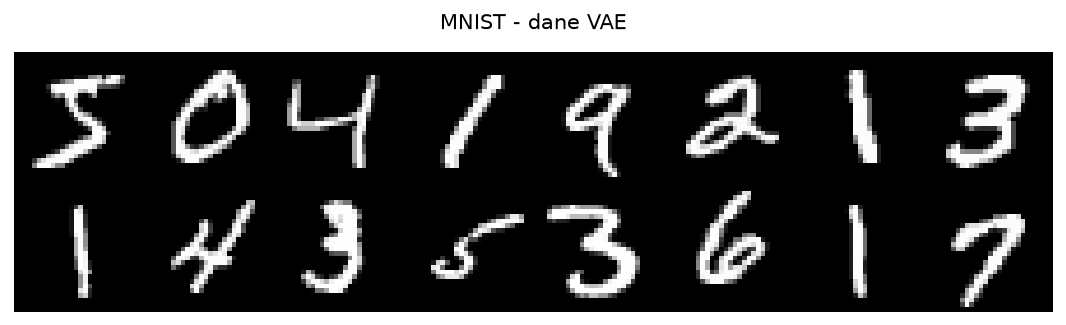

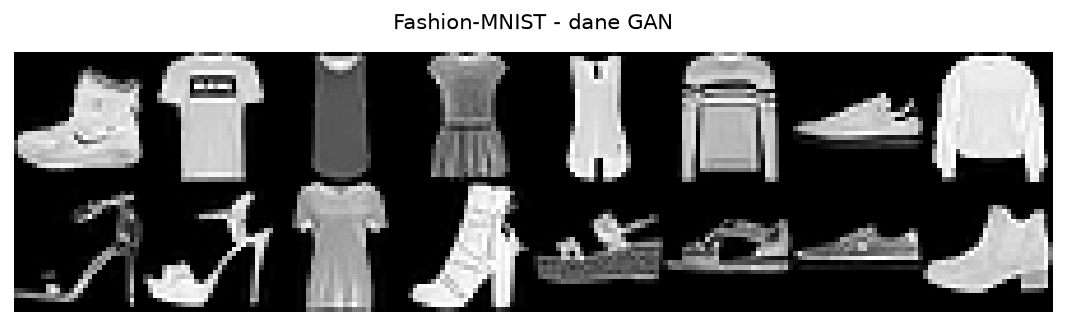

In [4]:
def plansza(obrazy, n_wierszy, n_kolumn, tytul='', zakres=(0, 1), rozmiar=1.0, slug='plansza'):
    obrazy = np.asarray(obrazy).reshape(-1, 28, 28)[:n_wierszy*n_kolumn]
    # Jeden obraz zbiorczy; brak zachodzacych na siebie tytulow podwykresow.
    canvas = np.full((28*n_wierszy, 28*n_kolumn), zakres[0], dtype='float32')
    for i, im in enumerate(obrazy):
        r, c = divmod(i, n_kolumn)
        canvas[r*28:(r+1)*28, c*28:(c+1)*28] = im
    fig, ax = plt.subplots(figsize=(n_kolumn*rozmiar, n_wierszy*rozmiar + .45))
    ax.imshow(canvas, cmap='gray', vmin=zakres[0], vmax=zakres[1])
    ax.set_title(tytul, fontsize=11, pad=12); ax.axis('off')
    fig.tight_layout(); rt.figure(fig, slug)

plansza(x_mnist[:16], 2, 8, 'MNIST - dane VAE', slug='dane_mnist')
plansza(x_fash[:16], 2, 8, 'Fashion-MNIST - dane GAN', zakres=(-1, 1), slug='dane_fashion')


## 1. Od autoenkodera do modelu generatywnego

Model generatywny uczy się (jawnie lub niejawnie) **rozkładu danych** $p(\mathbf{x})$, tak aby móc losować z niego nowe próbki. Na Lab 6 widzieliśmy, że dekoder zwykłego AE potrafi zamienić punkt $\mathbf{z}$ na obraz, ale **nie wiemy, skąd losować $\mathbf{z}$**: przestrzeń latentna AE ma dziury, nierówną gęstość i nieznany kształt. Wylosowanie punktu "pomiędzy" skupieniami daje często nieczytelny kształt.

**Pomysł VAE:** wymusić, żeby rozkład kodów był bliski prostemu rozkładowi a priori $p(\mathbf{z}) = \mathcal{N}(\mathbf{0}, I)$. Wtedy generowanie jest trywialne: losujemy $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, I)$ i podajemy do dekodera.

**Pomysł GAN:** nie modelujemy gęstości wprost. Generator $G(\mathbf{z})$ zamienia szum na obraz, a dyskryminator $D(\mathbf{x})$ ocenia, czy obraz jest prawdziwy. Generator uczy się "oszukiwać" dyskryminator.

| | AE (Lab 6) | VAE | GAN |
|---|---|---|---|
| Cel | rekonstrukcja | rekonstrukcja + regularny latent | realistyczne próbki |
| Enkoder | tak | tak (probabilistyczny) | brak |
| Losowanie nowych próbek | niepewne | tak, z $\mathcal{N}(0, I)$ | tak, z $\mathcal{N}(0, I)$ |
| Typowa jakość obrazów | - | lekko rozmyte | ostre |
| Stabilność treningu | wysoka | wysoka | niska (gra dwóch graczy) |

## 2. VAE - wariacyjny autoenkoder

### Teoria (W5)

Enkoder VAE nie zwraca jednego punktu, lecz **parametry rozkładu** $q_\phi(\mathbf{z}|\mathbf{x}) = \mathcal{N}(\boldsymbol{\mu}(\mathbf{x}), \operatorname{diag}\boldsymbol{\sigma}^2(\mathbf{x}))$. Dla stabilności numerycznej sieć zwraca $\log\boldsymbol{\sigma}^2$ (`z_log_var`) zamiast $\boldsymbol{\sigma}$ - może on przyjmować dowolne wartości rzeczywiste.

Uczymy maksymalizując dolne ograniczenie wiarygodności (ELBO), czyli minimalizując
$$\mathcal{L}(\mathbf{x}) = \underbrace{-\mathbb{E}_{q_\phi(\mathbf{z}|\mathbf{x})}\left[\log p_\theta(\mathbf{x}|\mathbf{z})\right]}_{\text{rekonstrukcja (BCE po pikselach)}} + \beta \cdot \underbrace{D_{KL}\left(q_\phi(\mathbf{z}|\mathbf{x}) \,\|\, \mathcal{N}(\mathbf{0}, I)\right)}_{\text{regularyzacja latentu}}$$
gdzie standardowy VAE ma $\beta = 1$. Dla rozkładów normalnych KL ma postać zamkniętą:
$$D_{KL} = -\frac{1}{2}\sum_{j=1}^{d}\left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right).$$

**Trik reparametryzacji:** losowanie $\mathbf{z} \sim \mathcal{N}(\boldsymbol\mu, \boldsymbol\sigma^2)$ nie jest różniczkowalne względem $\boldsymbol\mu, \boldsymbol\sigma$. Przepisujemy je jako
$$\mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma} \odot \boldsymbol{\epsilon}, \quad \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, I), \quad \boldsymbol\sigma = \exp\left(\tfrac{1}{2}\log\boldsymbol\sigma^2\right).$$
Losowość jest teraz w $\boldsymbol\epsilon$ (stała z punktu widzenia gradientu), a gradient płynie przez $\boldsymbol\mu$ i $\boldsymbol\sigma$.

**Intuicja dwóch składników:** sama rekonstrukcja dałaby zwykły AE (σ -> 0, kody rozrzucone byle jak). Sam KL ściągnąłby wszystkie kody do $\mathcal{N}(0, I)$ i dekoder nie miałby żadnej informacji. Kompromis daje przestrzeń jednocześnie **informatywną i regularną**.

### Zadanie 2.1 - warstwa próbkowania (trik reparametryzacji)

Uzupełnij metodę `call` warstwy `Sampling`: na wejściu para `(z_mean, z_log_var)`, na wyjściu $\mathbf{z} = \boldsymbol\mu + \exp(0.5 \log\boldsymbol\sigma^2)\odot\boldsymbol\epsilon$.

**Wymagania Keras 3:** używaj `keras.ops` (`ops.exp`, `ops.shape`) oraz `keras.random.normal(shape, seed=self.seed_generator)`. Nie używaj `tf.random.normal` ani `K.random_normal` z Keras 2 - działają inaczej lub nie istnieją.

**Kryteria sukcesu:** test w komórce poniżej - dla `z_mean = 3`, `z_log_var = log(0.25)` średnia próbek ok. 3.0, odchylenie standardowe ok. 0.5.

In [5]:
@keras.saving.register_keras_serializable(package='Lab07')
class Sampling(layers.Layer):
    def __init__(self, seed=42, **kwargs):
        super().__init__(**kwargs)
        self.seed = seed
        self.seed_generator = keras.random.SeedGenerator(seed)
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = keras.random.normal(ops.shape(z_mean), seed=self.seed_generator)
        # log_var to log wariancji, nie odchylenia. Stad 0.5 w exp().
        return z_mean + ops.exp(0.5*z_log_var) * eps
    def get_config(self):
        return {**super().get_config(), 'seed': self.seed}

mu_t = np.full((20000, 2), 3.0, dtype='float32')
lv_t = np.full((20000, 2), np.log(.25), dtype='float32')
z_t = ops.convert_to_numpy(Sampling(seed=SEED)([mu_t, lv_t]))
assert np.allclose(z_t.mean(0), 3, atol=.025)
assert np.allclose(z_t.std(0), .5, atol=.025)
RAPORT['zad_2_1'] = {'srednia': z_t.mean(0), 'std': z_t.std(0)}
RAPORT['testy']['sampling'] = True
print('Sampling - srednia:', z_t.mean(0), '| std:', z_t.std(0))
rt.done('2.1')



--- Komorka 10 ---
Sampling - srednia: [3.007594 2.997074] | std: [0.501583  0.4990576]


### Enkoder i dekoder VAE

Architektura konwolucyjna, jak CAE z Lab 6, ale enkoder ma **trzy wyjścia**: `z_mean`, `z_log_var` i wylosowane `z`. Latent ma tylko **2 wymiary**, żeby dało się go narysować. Dekoder kończy się `sigmoid` (piksele w $[0,1]$, strata BCE).

In [6]:
LATENT_VAE = 2

def zbuduj_enkoder_vae(latent_dim=LATENT_VAE):
    wej = keras.Input(shape=(28, 28, 1))
    h = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(wej)   # 14x14x32
    h = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(h)     # 7x7x64
    h = layers.Flatten()(h)
    h = layers.Dense(16, activation="relu")(h)
    z_mean = layers.Dense(latent_dim, name="z_mean")(h)         # średnia rozkładu q(z|x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(h)   # log wariancji (dowolna liczba rzeczywista)
    z = Sampling(seed=SEED, name="z")([z_mean, z_log_var])                 # próbka z rozkładu (trik reparametryzacji)
    return keras.Model(wej, [z_mean, z_log_var, z], name="vae_enkoder")

def zbuduj_dekoder_vae(latent_dim=LATENT_VAE):
    wej = keras.Input(shape=(latent_dim,))
    h = layers.Dense(7 * 7 * 64, activation="relu")(wej)
    h = layers.Reshape((7, 7, 64))(h)
    h = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(h)   # 14x14
    h = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(h)   # 28x28
    wyj = layers.Conv2D(1, 3, padding="same", activation="sigmoid")(h)
    return keras.Model(wej, wyj, name="vae_dekoder")

enc_vae = zbuduj_enkoder_vae()
dec_vae = zbuduj_dekoder_vae()
enc_vae.summary()



--- Komorka 12 ---
Model: "vae_enkoder"
┌───────────────────────────────┬───────────────────────────┬─────────────────┬────────────────────────────┐
│ Layer (type)                  │ Output Shape              │         Param # │ Connected to               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_layer (InputLayer)      │ (None, 28, 28, 1)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 14, 14, 32)        │             320 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 7, 7, 64)          │          18,496 │ conv2d[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────

### Model VAE z własnym `train_step` (Keras 3)

Strata VAE zależy od wewnętrznych tensorów (`z_mean`, `z_log_var`), więc nie pasuje do schematu `compile(loss=...)`. Nadpisujemy `train_step` w podklasie `keras.Model`. Wzorzec Keras 3 (backend TF):

1. `with tf.GradientTape() as tape:` - przebieg w przód i policzenie straty,
2. `tape.gradient(strata, self.trainable_weights)`,
3. `self.optimizer.apply_gradients(zip(grads, self.trainable_weights))`,
4. aktualizacja metryk-śledzących (`keras.metrics.Mean`) i zwrócenie słownika `{nazwa: wartość}`.

**Pułapki Keras 3 vs Keras 2 (często w starych tutorialach):**
- nie ma `self.compiled_loss` / `self.compiled_metrics` w starym stylu - używamy własnych `keras.metrics.Mean`,
- metryki muszą być zwrócone przez właściwość `metrics`, żeby Keras resetował je na początku każdej epoki,
- `fit(x)` bez `y` przekazuje do `train_step` same dane albo krotkę - obsługujemy oba przypadki,
- operacje matematyczne przez `keras.ops`, nie `K.` (moduł `keras.backend` z Keras 2 jest okrojony).

**Skala straty:** rekonstrukcję **sumujemy po pikselach** (784 składniki), a KL po wymiarach latentu, i dopiero potem uśredniamy po batchu. Jeśli uśrednisz BCE po pikselach, rekonstrukcja będzie ok. 784 razy "słabsza" od KL i VAE wygeneruje same rozmyte średnie (*posterior collapse*).

### Zadanie 2.2 - strata VAE w `train_step`

W metodzie `oblicz_straty` uzupełnij:
- `rec_loss` - BCE między `data` a `rekonstrukcja`, zsumowana po osiach (1, 2) (kanał już redukuje `keras.losses.binary_crossentropy`), uśredniona po batchu,
- `kl_loss` - wzór na $D_{KL}$ z teorii, zsumowany po wymiarach latentu (oś 1), uśredniony po batchu.

Metodę `oblicz_straty` wykorzystują zarówno `train_step`, jak i `test_step` (walidacja).

**Kryteria sukcesu:** trening startuje, `kl_loss` jest dodatnia, `loss` = `rec_loss` + β·`kl_loss` maleje. W pełnym trybie po 30 epokach `loss` ok. 150-160, `kl_loss` ok. 5-7.

In [7]:
class VAE(keras.Model):
    def __init__(self, enkoder, dekoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.enkoder, self.dekoder, self.beta = enkoder, dekoder, float(beta)
        self.loss_tracker = keras.metrics.Mean(name='loss')
        self.rec_tracker = keras.metrics.Mean(name='rec_loss')
        self.kl_tracker = keras.metrics.Mean(name='kl_loss')
    @property
    def metrics(self):
        return [self.loss_tracker, self.rec_tracker, self.kl_tracker]
    def call(self, x, training=False):
        _, _, z = self.enkoder(x, training=training)
        return self.dekoder(z, training=training)
    def oblicz_straty(self, data, training):
        z_mean, z_log_var, z = self.enkoder(data, training=training)
        rek = self.dekoder(z, training=training)
        # BCE redukuje kanal, zostaje (batch, 28, 28). Sumujemy piksele.
        rec_loss = ops.mean(ops.sum(keras.losses.binary_crossentropy(data, rek), axis=(1, 2)))
        kl_loss = ops.mean(ops.sum(-.5*(1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var)), axis=1))
        return rec_loss + self.beta*kl_loss, rec_loss, kl_loss
    def _aktualizuj(self, total, rec, kl, batch):
        for metric, value in zip(self.metrics, (total, rec, kl)):
            # Ostatni, mniejszy batch nie dostaje wagi calego batcha.
            metric.update_state(value, sample_weight=ops.cast(batch, 'float32'))
        return {m.name: m.result() for m in self.metrics}
    def train_step(self, data):
        data = keras.utils.unpack_x_y_sample_weight(data)[0]
        with tf.GradientTape() as tape:
            total, rec, kl = self.oblicz_straty(data, training=True)
            tf.debugging.assert_all_finite(total, 'VAE: strata NaN/inf')
        grads = tape.gradient(total, self.trainable_weights)
        if any(g is None for g in grads):
            raise RuntimeError('VAE: gradient nie dochodzi do wszystkich wag')
        for g in grads:
            tf.debugging.assert_all_finite(g, 'VAE: gradient NaN/inf')
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return self._aktualizuj(total, rec, kl, ops.shape(data)[0])
    def test_step(self, data):
        data = keras.utils.unpack_x_y_sample_weight(data)[0]
        total, rec, kl = self.oblicz_straty(data, training=False)
        tf.debugging.assert_all_finite(total, 'VAE: walidacja NaN/inf')
        return self._aktualizuj(total, rec, kl, ops.shape(data)[0])

# Test skali: stale p=0.5 daje 784*ln(2), a N(0,I) ma KL=0.
zeros = ops.zeros((2, 28, 28, 1))
half = ops.ones_like(zeros)*.5
bce_test = float(ops.convert_to_numpy(ops.mean(ops.sum(keras.losses.binary_crossentropy(zeros, half), axis=(1, 2)))))
assert np.isclose(bce_test, 784*np.log(2), rtol=1e-5)
zero_kl = ops.sum(-.5*(1 + ops.zeros((2,2)) - ops.zeros((2,2)) - ops.exp(ops.zeros((2,2)))))
assert np.isclose(float(ops.convert_to_numpy(zero_kl)), 0)
RAPORT['testy']['skala_bce_i_kl'] = True
print('BCE dla p=0.5:', bce_test, '| KL N(0,I): 0')



--- Komorka 15 ---
BCE dla p=0.5: 543.4276123046875 | KL N(0,I): 0


In [8]:
vae = VAE(enc_vae, dec_vae, beta=1.0)
# Zbuduj model przed save_weights; samo oblicz_straty nie wywoluje VAE.call.
_ = vae(x_vae_train[:2], training=False)
vae.compile(optimizer=keras.optimizers.Adam(1e-3), jit_compile=False)
t0 = time.perf_counter()
hist_vae = vae.fit(ds_obrazow(x_vae_train, shuffle=True),
                  validation_data=ds_obrazow(x_vae_val), epochs=EPOKI_VAE,
                  verbose=2, callbacks=[KontrolaEpoki('vae')])
rt.history(hist_vae, 'vae')
RAPORT['zad_2_2'] = {'czas_s': round(time.perf_counter()-t0, 2),
                    'parametry': vae.count_params(),
                    'train_ostatnie': {k: float(v[-1]) for k,v in hist_vae.history.items()},
                    'ocena_test': vae.evaluate(ds_obrazow(x_mnist_te), return_dict=True, verbose=0)}
vae.save_weights(rt.models / 'vae_ostatni.weights.h5')
# Te modele pozwalaja pozniej odtworzyc rysunki bez ponownego treningu.
enc_vae.save(rt.models / 'vae_enkoder.keras')
dec_vae.save(rt.models / 'vae_dekoder.keras')
if hist_vae.history['kl_loss'][-1] < .01:
    rt.warn('KL VAE bliskie zeru: obejrzyj rekonstrukcje, mozliwy posterior collapse lub za krotki trening.')
rt.done('2.2')



--- Komorka 16 ---
Epoch 1/30


422/422 - 21s - 49ms/step - kl_loss: 3.1575 - loss: 214.6218 - rec_loss: 211.4644 - val_kl_loss: 4.5204 - val_loss: 178.7628 - val_rec_loss: 174.2424
Epoch 2/30


422/422 - 18s - 43ms/step - kl_loss: 4.7569 - loss: 169.2450 - rec_loss: 164.4881 - val_kl_loss: 5.0042 - val_loss: 165.1665 - val_rec_loss: 160.1623
Epoch 3/30


422/422 - 18s - 42ms/step - kl_loss: 5.1540 - loss: 162.5007 - rec_loss: 157.3467 - val_kl_loss: 5.2508 - val_loss: 161.4918 - val_rec_loss: 156.2409
Epoch 4/30


422/422 - 18s - 42ms/step - kl_loss: 5.4503 - loss: 159.3661 - rec_loss: 153.9158 - val_kl_loss: 5.4288 - val_loss: 158.9188 - val_rec_loss: 153.4901
Epoch 5/30


...

422/422 - 18s - 42ms/step - kl_loss: 6.2868 - loss: 149.1044 - rec_loss: 142.8177 - val_kl_loss: 6.2945 - val_loss: 152.0217 - val_rec_loss: 145.7271
Epoch 27/30


422/422 - 19s - 44ms/step - kl_loss: 6.3099 - loss: 148.9919 - rec_loss: 142.6820 - val_kl_loss: 6.2918 - val_loss: 152.6485 - val_rec_loss: 146.3567
Epoch 28/30


422/422 - 18s - 42ms/step - kl_loss: 6.3195 - loss: 148.8390 - rec_loss: 142.5195 - val_kl_loss: 6.2996 - val_loss: 152.1339 - val_rec_loss: 145.8343
Epoch 29/30


422/422 - 18s - 43ms/step - kl_loss: 6.3225 - loss: 148.6298 - rec_loss: 142.3074 - val_kl_loss: 6.2554 - val_loss: 151.4581 - val_rec_loss: 145.2028
Epoch 30/30


422/422 - 18s - 42ms/step - kl_loss: 6.3362 - loss: 148.5370 - rec_loss: 142.2007 - val_kl_loss: 6.2959 - val_loss: 151.4268 - val_rec_loss: 145.1309



--- Komorka 17 ---


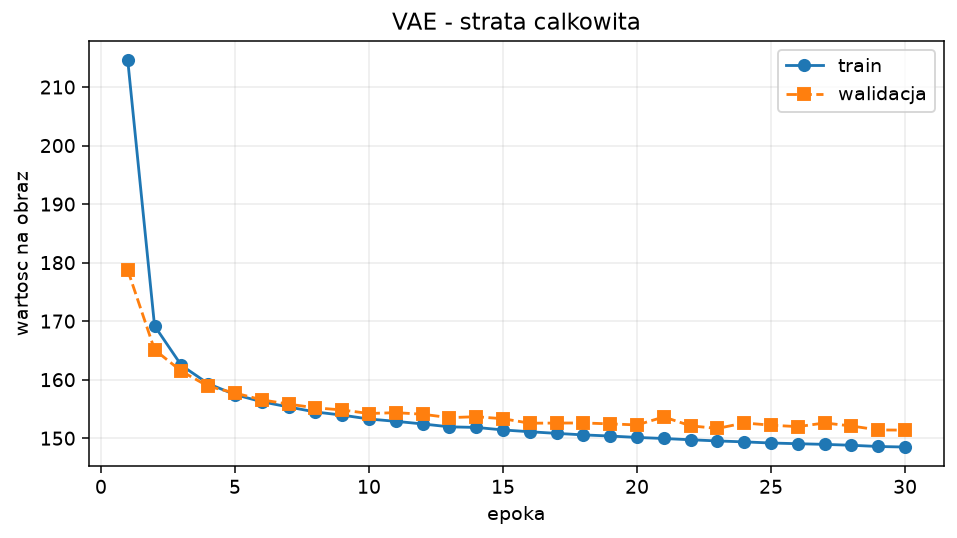

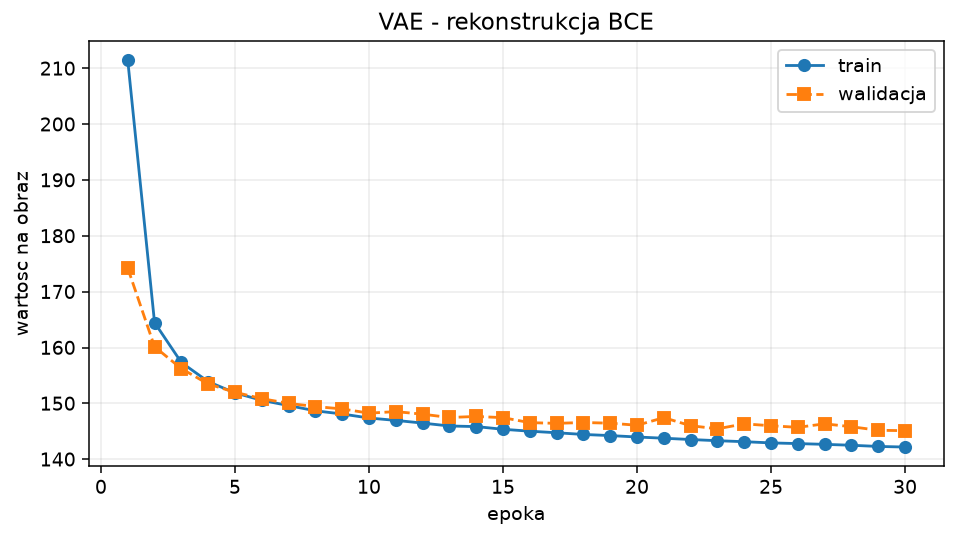

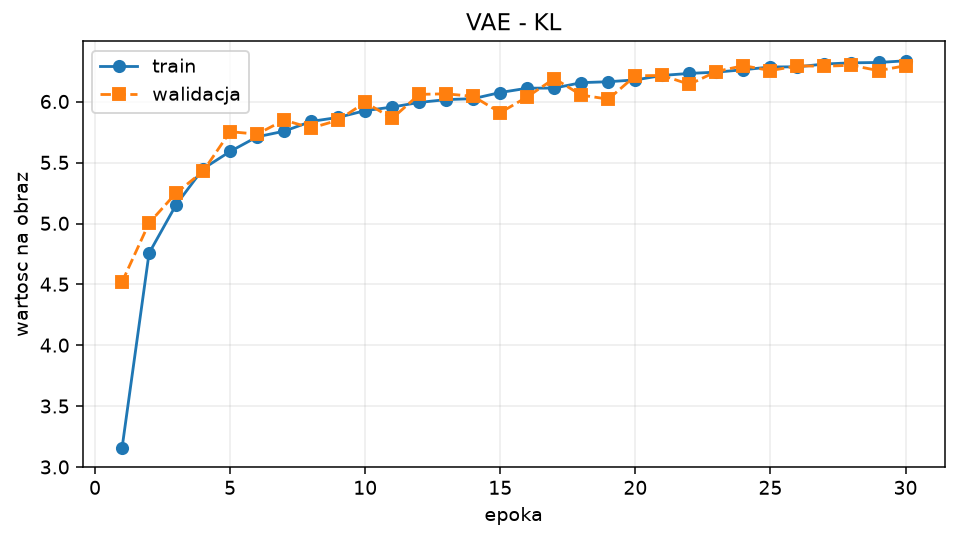

In [9]:
for key, title in [('loss','VAE - strata calkowita'), ('rec_loss','VAE - rekonstrukcja BCE'), ('kl_loss','VAE - KL')]:
    rysuj_metryke(hist_vae, key, title, 'vae_'+key)


**Co obserwować:** KL na początku zwykle **rośnie** (enkoder zaczyna kodować informację, odchodząc od $\mathcal{N}(0, I)$), a potem się stabilizuje; rekonstrukcja monotonicznie maleje. To naturalna "negocjacja" między dwoma składnikami. Jeśli KL spada do ok. 0 i tam zostaje - latent przestał nieść informację (*posterior collapse*), sprawdź skalę `rec_loss`.

### Przestrzeń latentna VAE i generowanie z siatki

Rysujemy `z_mean` dla obrazów testowych (bez losowania - to "środek" kodu obrazu). Następnie dekodujemy regularną siatkę punktów. Siatkę budujemy na **kwantylach rozkładu normalnego** (`norm.ppf`), bo a priori $\mathbf{z} \sim \mathcal{N}(0, I)$ - dzięki temu punkty są gęściej tam, gdzie leży większość masy prawdopodobieństwa.


--- Komorka 19 ---


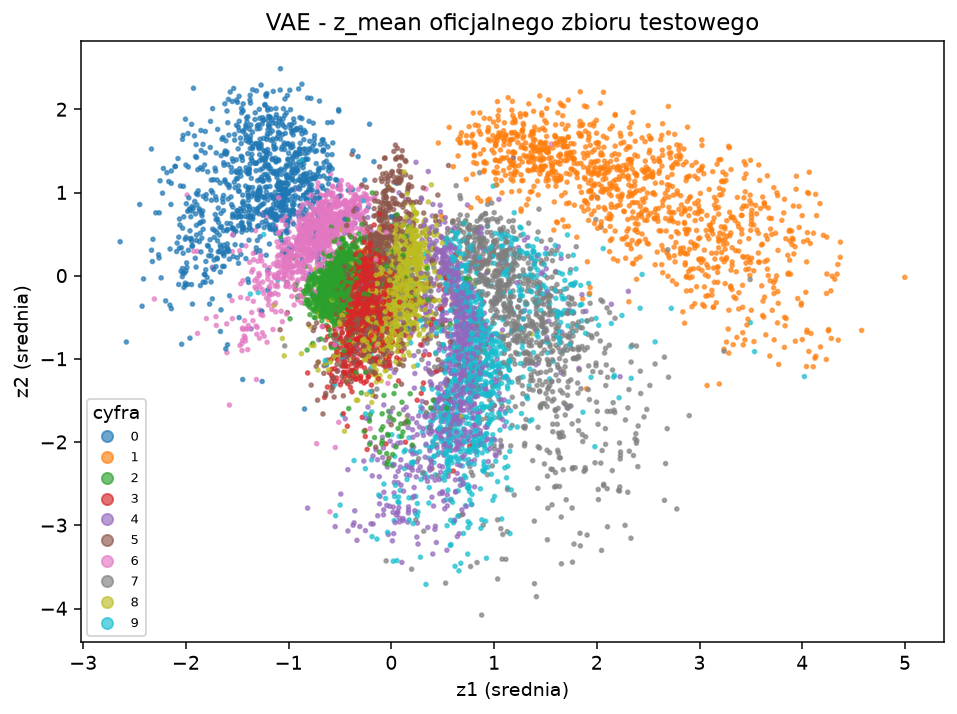

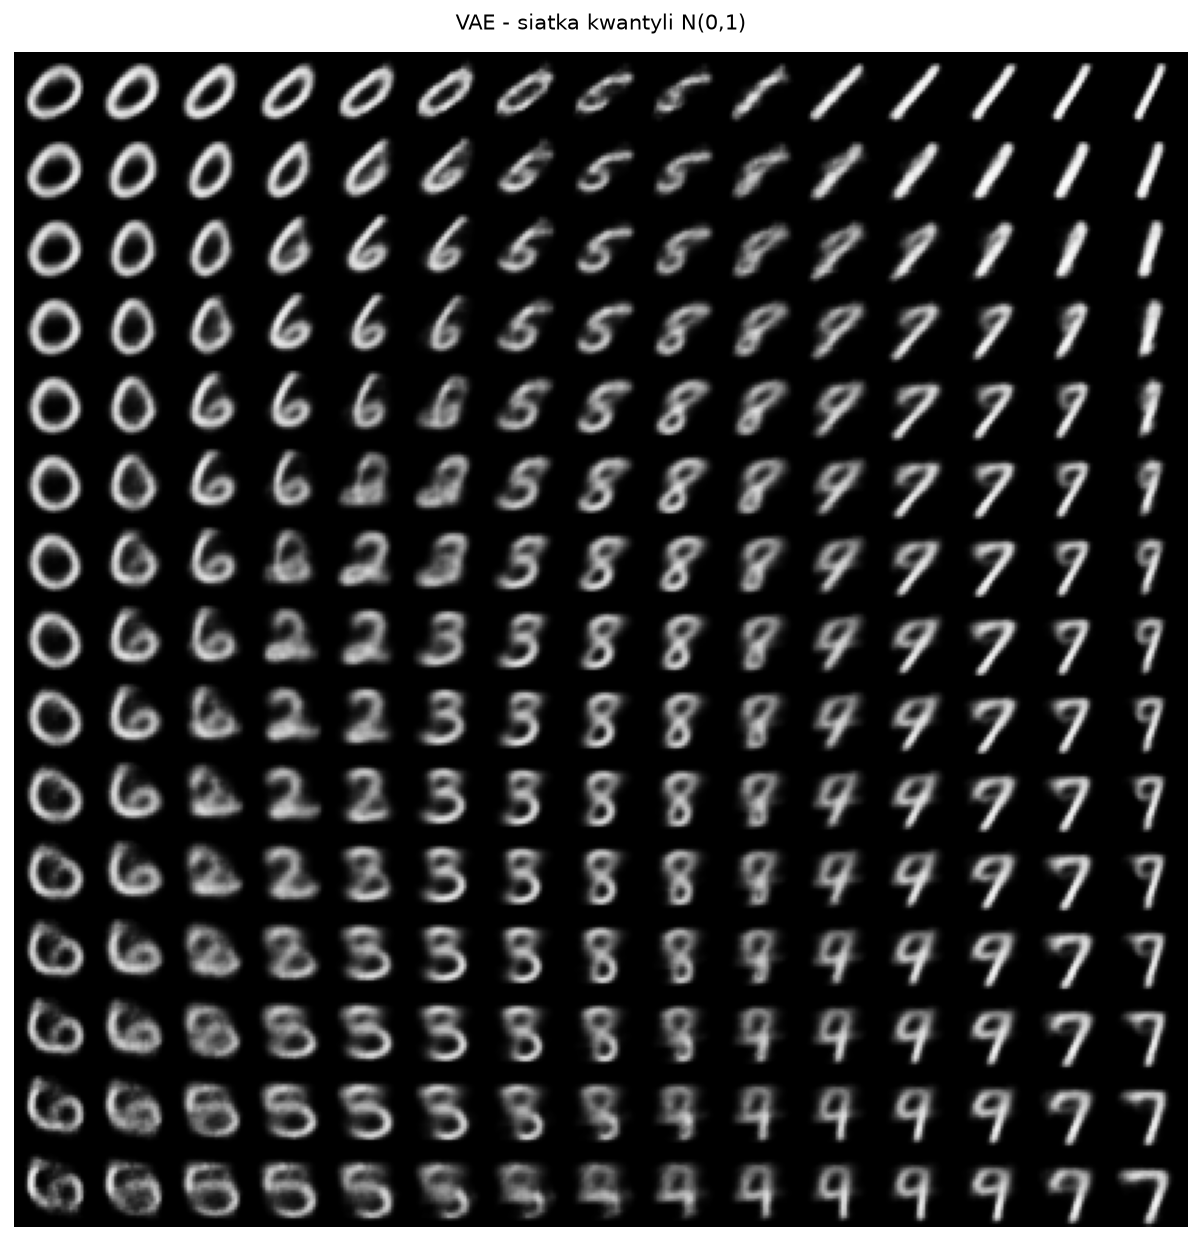

Latent VAE: {'srednia_mu': array([ 0.2531087 , -0.10974073], dtype=float32), 'std_mu': array([1.1202399, 0.9825303], dtype=float32), 'srednia_sigma': array([0.04552231, 0.05962112], dtype=float32)}


In [10]:
z_mean_te, z_log_var_te, _ = enc_vae.predict(x_mnist_te, batch_size=128, verbose=0)
fig, ax = plt.subplots(figsize=(7.2, 5.4))
sc = ax.scatter(z_mean_te[:,0], z_mean_te[:,1], c=y_mnist_te, s=4, alpha=.65, cmap='tab10')
ax.legend(*sc.legend_elements(), title='cyfra', fontsize=7)
ax.set(xlabel='z1 (srednia)', ylabel='z2 (srednia)', title='VAE - z_mean oficjalnego zbioru testowego')
fig.tight_layout(); rt.figure(fig, 'vae_latent_test')
n = 15
q = np.linspace(.05, .95, n)
siatka_z = np.array([[norm.ppf(a),norm.ppf(b)] for b in q[::-1] for a in q], dtype='float32')
gen = dec_vae.predict(siatka_z, verbose=0)
plansza(gen, n, n, 'VAE - siatka kwantyli N(0,1)', rozmiar=.6, slug='vae_siatka_kwantyli')
RAPORT['latent_vae'] = {'srednia_mu': z_mean_te.mean(0), 'std_mu': z_mean_te.std(0),
                       'srednia_sigma': np.exp(.5*z_log_var_te).mean(0)}
print('Latent VAE:', RAPORT['latent_vae']); rt.save()



--- Komorka 20 ---


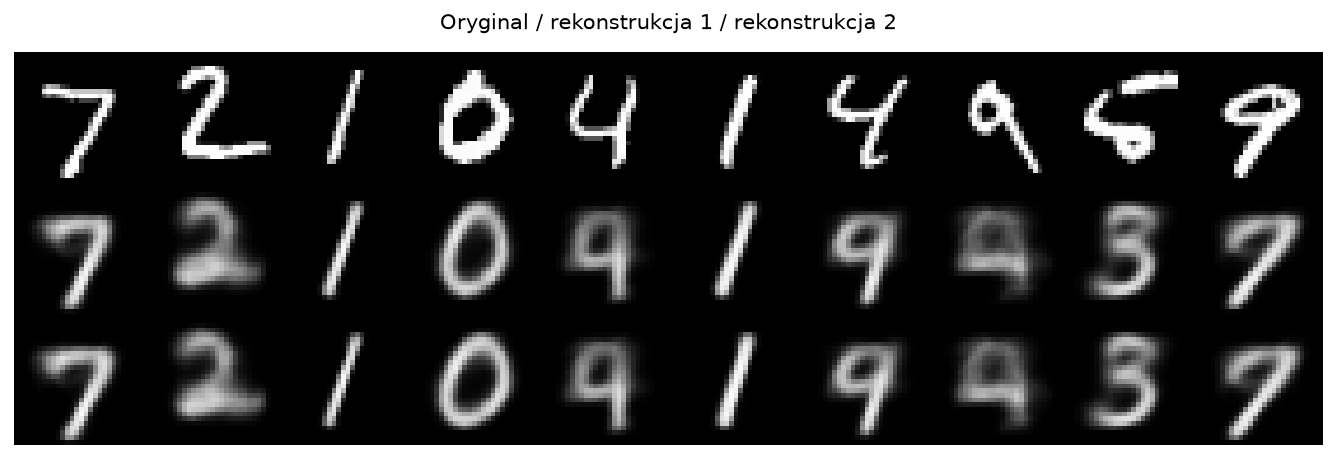

Srednia roznica dwoch losowan: 0.011580592021346092


In [11]:
rek_1 = vae.predict(x_mnist_te[:10], verbose=0)
rek_2 = vae.predict(x_mnist_te[:10], verbose=0)
plansza(np.concatenate([x_mnist_te[:10],rek_1,rek_2]), 3, 10,
        'Oryginal / rekonstrukcja 1 / rekonstrukcja 2', slug='vae_rekonstrukcje')
RAPORT['roznica_dwoch_losowan_vae'] = float(np.abs(rek_1-rek_2).mean())
print('Srednia roznica dwoch losowan:', RAPORT['roznica_dwoch_losowan_vae']); rt.save()


**Typowe błędy przy VAE:**
- strata rekonstrukcji uśredniona zamiast zsumowana po pikselach - KL dominuje, latent "zapada się",
- znak w KL (strata ujemna i rosnąca),
- `ops.exp(z_log_var)` zamiast `ops.exp(0.5 * z_log_var)` w próbkowaniu,
- wizualizacja `z` (losowe) zamiast `z_mean` - wykres jest "zaszumiony",
- brak właściwości `metrics` - wartości w logach kumulują się między epokami zamiast być resetowane.


--- Komorka 22 ---


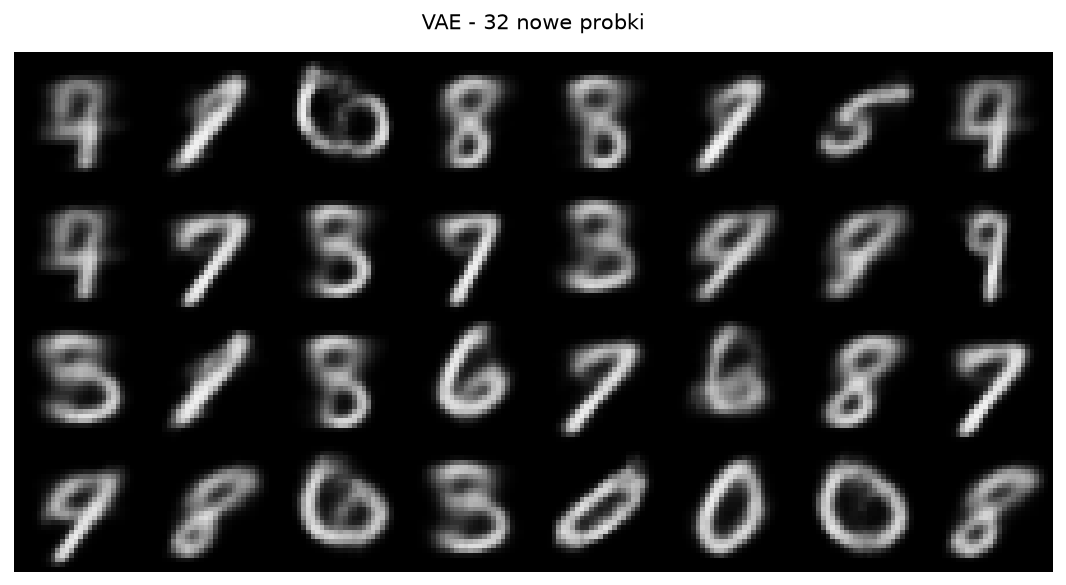

In [12]:
z_los = np.random.default_rng(SEED).normal(size=(32, LATENT_VAE)).astype('float32')
plansza(dec_vae.predict(z_los, verbose=0), 4, 8, 'VAE - 32 nowe probki', slug='vae_losowe_probki')


### Zadanie 2.3 - interpolacja: przestrzeń pikseli vs przestrzeń latentna

Weź dwa obrazy testowe różnych cyfr (np. pierwsze wystąpienie 1 i 8: `x_a`, `x_b`).
1. **Interpolacja w pikselach:** $(1-t)\mathbf{x}_a + t\,\mathbf{x}_b$ dla 10 wartości $t \in [0, 1]$.
2. **Interpolacja w latencie:** zakoduj oba obrazy (`z_mean`), interpoluj $\mathbf{z}_t = (1-t)\mathbf{z}_a + t\,\mathbf{z}_b$ i zdekoduj.
3. Narysuj oba wiersze (zmienne `wiersz_piksele`, `wiersz_latent` - tablice `(10, 28, 28)`).

**Kryteria sukcesu:** w pikselach widać "nałożenie dwóch obrazów" (przenikanie), w latencie - stopniową zmianę kształtu, każdy obraz pośredni wygląda jak (jakaś) cyfra.


--- Komorka 24 ---


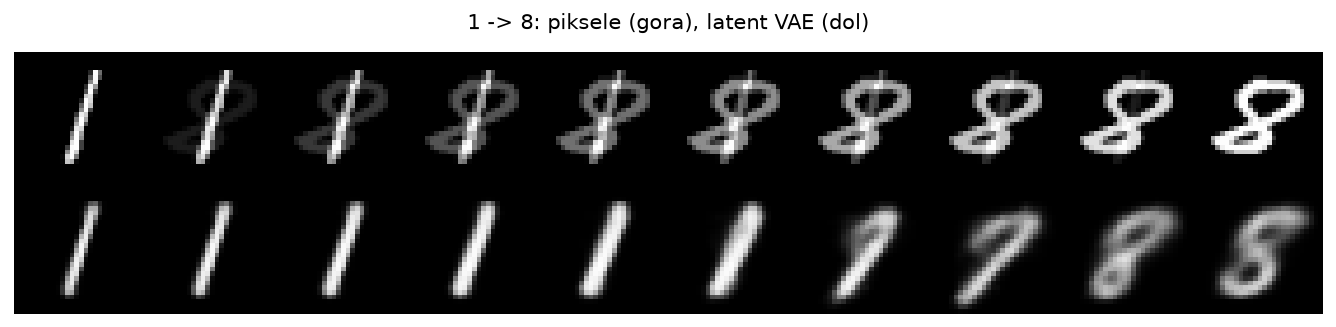

In [13]:
ts = np.linspace(0, 1, 10, dtype='float32')
if not np.any(y_mnist_te == 1) or not np.any(y_mnist_te == 8):
    raise ValueError('W probce testowej brakuje cyfry 1 albo 8')
x_a = x_mnist_te[np.flatnonzero(y_mnist_te == 1)[0]]
x_b = x_mnist_te[np.flatnonzero(y_mnist_te == 8)[0]]
wiersz_piksele = np.array([(1-t)*x_a + t*x_b for t in ts]).reshape(10,28,28)
z_a_vae, _, _ = enc_vae.predict(x_a[None], verbose=0)
z_b_vae, _, _ = enc_vae.predict(x_b[None], verbose=0)
z_interp = (1-ts[:,None])*z_a_vae + ts[:,None]*z_b_vae
wiersz_latent = dec_vae.predict(z_interp, verbose=0).reshape(10,28,28)
assert np.allclose(wiersz_piksele[0], x_a[...,0])
assert np.allclose(wiersz_piksele[-1], x_b[...,0])
plansza(np.concatenate([wiersz_piksele, wiersz_latent]), 2, 10,
        '1 -> 8: piksele (gora), latent VAE (dol)', slug='vae_interpolacja')
RAPORT['zad_2_3'] = {'ksztalt_piksele': list(wiersz_piksele.shape),
                    'ksztalt_latent': list(wiersz_latent.shape)}
RAPORT['testy']['interpolacja_vae'] = True
rt.done('2.3')


### Zadanie 2.4 - hipoteza: wpływ wagi KL ($\beta$)

**Hipoteza (UGŁ_U01):** *zwiększenie $\beta$ poprawia regularność przestrzeni latentnej (kody bliższe $\mathcal{N}(0,I)$) kosztem jakości rekonstrukcji; zmniejszenie $\beta$ działa odwrotnie.*

1. Wytrenuj trzy VAE (nowe enkodery i dekodery!) z $\beta \in \{0.1, 1, 4\}$ przez `EPOKI_KROTKO` epok.
2. Dla każdego zapisz w `wyniki_beta` (lista słowników): `beta`, końcowe `rec_loss`, `kl_loss` (z historii) oraz odchylenie standardowe `z_mean` na teście.
3. Narysuj trzy wykresy przestrzeni latentnej obok siebie.
4. Napisz 2-3 zdania wniosku: czy hipoteza się potwierdziła?

**Wskazówka:** ponieważ `rec_loss` jest sumą po 784 pikselach, $\beta = 4$ to wciąż umiarkowana regularyzacja; przy $\beta \to 0$ VAE zbliża się do zwykłego AE.


--- Komorka 26 ---
Epoch 1/10


422/422 - 21s - 50ms/step - kl_loss: 12.7945 - loss: 212.2969 - rec_loss: 211.0174 - val_kl_loss: 8.4238 - val_loss: 185.7850 - val_rec_loss: 184.9426
Epoch 2/10


422/422 - 18s - 43ms/step - kl_loss: 11.1399 - loss: 167.9614 - rec_loss: 166.8474 - val_kl_loss: 10.2488 - val_loss: 162.5984 - val_rec_loss: 161.5735
Epoch 3/10


422/422 - 18s - 43ms/step - kl_loss: 9.9862 - loss: 159.5479 - rec_loss: 158.5493 - val_kl_loss: 9.6743 - val_loss: 157.7724 - val_rec_loss: 156.8050
Epoch 4/10


422/422 - 19s - 44ms/step - kl_loss: 9.9598 - loss: 155.5319 - rec_loss: 154.5360 - val_kl_loss: 10.0761 - val_loss: 154.7732 - val_rec_loss: 153.7656
Epoch 5/10


...

422/422 - 18s - 42ms/step - kl_loss: 10.1422 - loss: 151.4537 - rec_loss: 150.4395 - val_kl_loss: 10.0203 - val_loss: 151.3801 - val_rec_loss: 150.3781
Epoch 7/10


422/422 - 20s - 46ms/step - kl_loss: 10.1439 - loss: 150.2006 - rec_loss: 149.1862 - val_kl_loss: 10.1887 - val_loss: 150.6900 - val_rec_loss: 149.6712
Epoch 8/10


422/422 - 21s - 49ms/step - kl_loss: 10.1525 - loss: 149.2755 - rec_loss: 148.2604 - val_kl_loss: 10.2891 - val_loss: 149.6630 - val_rec_loss: 148.6341
Epoch 9/10


422/422 - 20s - 48ms/step - kl_loss: 10.2052 - loss: 148.4684 - rec_loss: 147.4479 - val_kl_loss: 9.7540 - val_loss: 149.1461 - val_rec_loss: 148.1708
Epoch 10/10


422/422 - 22s - 51ms/step - kl_loss: 10.2750 - loss: 147.7216 - rec_loss: 146.6941 - val_kl_loss: 10.4786 - val_loss: 148.6192 - val_rec_loss: 147.5713


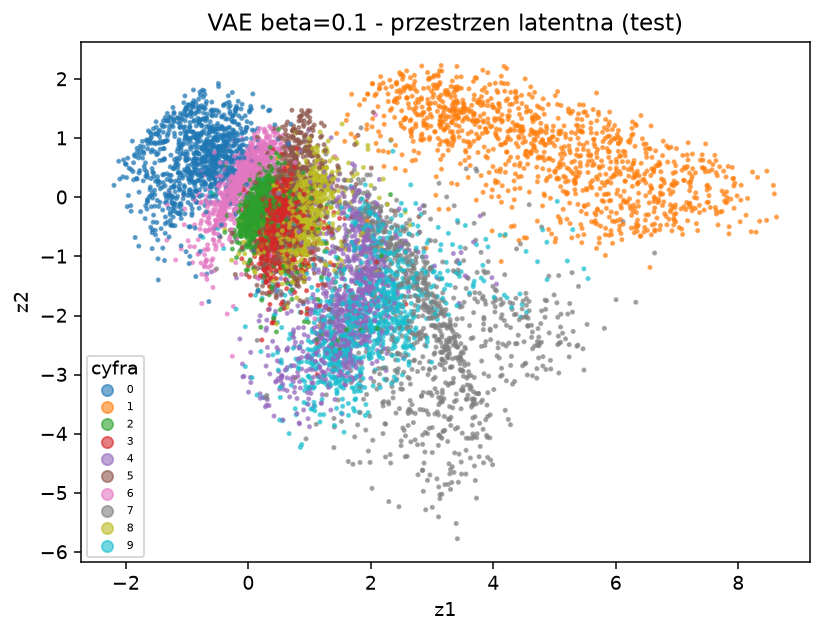

Epoch 1/10


422/422 - 23s - 55ms/step - kl_loss: 3.1575 - loss: 214.6218 - rec_loss: 211.4644 - val_kl_loss: 4.5204 - val_loss: 178.7628 - val_rec_loss: 174.2424
Epoch 2/10


422/422 - 20s - 48ms/step - kl_loss: 4.7569 - loss: 169.2450 - rec_loss: 164.4881 - val_kl_loss: 5.0042 - val_loss: 165.1665 - val_rec_loss: 160.1623
Epoch 3/10


422/422 - 20s - 48ms/step - kl_loss: 5.1540 - loss: 162.5007 - rec_loss: 157.3467 - val_kl_loss: 5.2508 - val_loss: 161.4918 - val_rec_loss: 156.2409
Epoch 4/10


422/422 - 21s - 51ms/step - kl_loss: 5.4503 - loss: 159.3661 - rec_loss: 153.9158 - val_kl_loss: 5.4288 - val_loss: 158.9188 - val_rec_loss: 153.4901
Epoch 5/10


...

422/422 - 21s - 51ms/step - kl_loss: 5.7122 - loss: 156.2794 - rec_loss: 150.5672 - val_kl_loss: 5.7344 - val_loss: 156.6008 - val_rec_loss: 150.8664
Epoch 7/10


422/422 - 24s - 56ms/step - kl_loss: 5.7583 - loss: 155.3823 - rec_loss: 149.6241 - val_kl_loss: 5.8495 - val_loss: 155.8667 - val_rec_loss: 150.0172
Epoch 8/10


422/422 - 22s - 52ms/step - kl_loss: 5.8386 - loss: 154.5276 - rec_loss: 148.6891 - val_kl_loss: 5.7843 - val_loss: 155.2369 - val_rec_loss: 149.4526
Epoch 9/10


422/422 - 21s - 50ms/step - kl_loss: 5.8715 - loss: 153.9890 - rec_loss: 148.1175 - val_kl_loss: 5.8485 - val_loss: 154.8710 - val_rec_loss: 149.0224
Epoch 10/10


422/422 - 21s - 51ms/step - kl_loss: 5.9272 - loss: 153.3251 - rec_loss: 147.3981 - val_kl_loss: 5.9950 - val_loss: 154.2640 - val_rec_loss: 148.2690


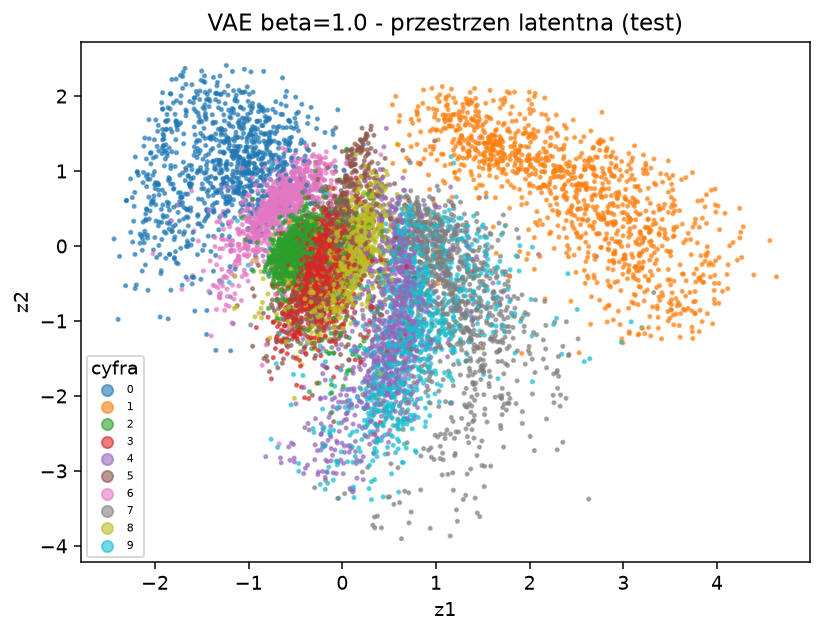

Epoch 1/10


422/422 - 24s - 57ms/step - kl_loss: 0.5536 - loss: 224.0175 - rec_loss: 221.8032 - val_kl_loss: 0.8748 - val_loss: 202.1357 - val_rec_loss: 198.6367
Epoch 2/10


422/422 - 21s - 50ms/step - kl_loss: 1.1926 - loss: 199.0121 - rec_loss: 194.2419 - val_kl_loss: 1.3975 - val_loss: 196.1764 - val_rec_loss: 190.5864
Epoch 3/10


422/422 - 21s - 51ms/step - kl_loss: 2.2759 - loss: 189.1489 - rec_loss: 180.0453 - val_kl_loss: 3.0270 - val_loss: 184.1005 - val_rec_loss: 171.9927
Epoch 4/10


422/422 - 20s - 48ms/step - kl_loss: 3.1980 - loss: 180.6826 - rec_loss: 167.8905 - val_kl_loss: 3.3454 - val_loss: 179.2984 - val_rec_loss: 165.9168
Epoch 5/10


...

422/422 - 21s - 50ms/step - kl_loss: 3.6084 - loss: 175.3982 - rec_loss: 160.9643 - val_kl_loss: 3.6197 - val_loss: 175.5932 - val_rec_loss: 161.1144
Epoch 7/10


422/422 - 21s - 49ms/step - kl_loss: 3.7029 - loss: 174.0452 - rec_loss: 159.2334 - val_kl_loss: 3.8452 - val_loss: 175.2226 - val_rec_loss: 159.8418
Epoch 8/10


422/422 - 20s - 48ms/step - kl_loss: 3.7883 - loss: 173.0993 - rec_loss: 157.9463 - val_kl_loss: 3.7037 - val_loss: 173.5609 - val_rec_loss: 158.7462
Epoch 9/10


422/422 - 21s - 50ms/step - kl_loss: 3.8358 - loss: 172.2596 - rec_loss: 156.9164 - val_kl_loss: 3.7952 - val_loss: 172.9533 - val_rec_loss: 157.7725
Epoch 10/10


422/422 - 21s - 49ms/step - kl_loss: 3.8707 - loss: 171.6087 - rec_loss: 156.1258 - val_kl_loss: 3.8050 - val_loss: 172.6780 - val_rec_loss: 157.4578


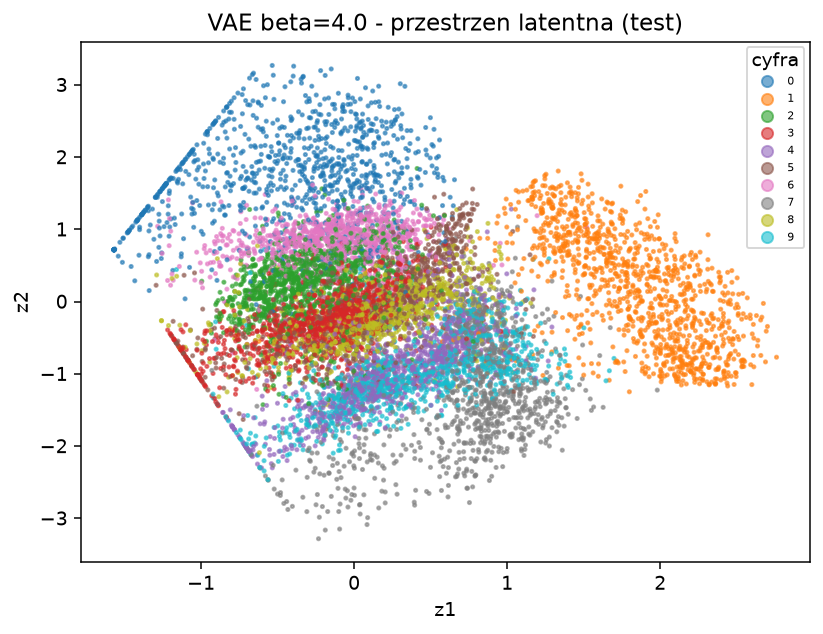

 beta   rec_loss   kl_loss  val_rec_loss  val_kl_loss  std_mu_z1_test  std_mu_z2_test  mean_sigma_test  epoki
  0.1 146.694077 10.275041    147.571320    10.478574        1.762032        1.247266         0.018378     10
  1.0 147.398087  5.927158    148.268997     5.995002        1.111417        0.982083         0.058323     10
  4.0 156.125809  3.870728    157.457825     3.805048        0.773299        1.010496         0.152047     10


Beta: zgodna z kierunkiem hipotezy


In [14]:
wyniki_beta = []
for beta in (.1, 1., 4.):
    # Ten sam start, nowy model i optimizer. Nie kontynuujemy poprzedniego VAE.
    keras.utils.set_random_seed(SEED)
    en_b, de_b = zbuduj_enkoder_vae(), zbuduj_dekoder_vae()
    v_b = VAE(en_b, de_b, beta=beta)
    _ = v_b(x_vae_train[:2], training=False)
    v_b.compile(optimizer=keras.optimizers.Adam(1e-3), jit_compile=False)
    h_b = v_b.fit(ds_obrazow(x_vae_train, shuffle=True),
                 validation_data=ds_obrazow(x_vae_val), epochs=EPOKI_KROTKO,
                 verbose=2, callbacks=[KontrolaEpoki('beta_'+str(beta))])
    rt.history(h_b, 'beta_'+str(beta).replace('.','_'))
    mu_b, lv_b, _ = en_b.predict(x_mnist_te, batch_size=128, verbose=0)
    results = {'beta': beta, 'rec_loss': float(h_b.history['rec_loss'][-1]),
               'kl_loss': float(h_b.history['kl_loss'][-1]),
               'val_rec_loss': float(h_b.history['val_rec_loss'][-1]),
               'val_kl_loss': float(h_b.history['val_kl_loss'][-1]),
               'std_mu_z1_test': float(mu_b.std(0)[0]), 'std_mu_z2_test': float(mu_b.std(0)[1]),
               'mean_sigma_test': float(np.exp(.5*lv_b).mean()), 'epoki': EPOKI_KROTKO}
    wyniki_beta.append(results)
    fig, ax = plt.subplots(figsize=(6.2,4.8))
    sc = ax.scatter(mu_b[:,0], mu_b[:,1], c=y_mnist_te, s=3, alpha=.6, cmap='tab10')
    ax.set(xlabel='z1', ylabel='z2', title=f'VAE beta={beta} - przestrzen latentna (test)')
    ax.legend(*sc.legend_elements(), fontsize=6, title='cyfra')
    fig.tight_layout(); rt.figure(fig, 'beta_'+str(beta).replace('.','_')+'_latent')
    del v_b, en_b, de_b
rt.table(pd.DataFrame(wyniki_beta), 'porownanie_beta.csv')
rec = np.array([r['rec_loss'] for r in wyniki_beta])
kl = np.array([r['kl_loss'] for r in wyniki_beta])
trend_rec = bool(np.all(np.diff(rec) >= 0))
trend_kl = bool(np.all(np.diff(kl) <= 0))
werdykt_beta = ('zgodna z kierunkiem hipotezy' if trend_rec and trend_kl else
                'czesciowo zgodna' if trend_rec or trend_kl else 'niepotwierdzona w tym przebiegu')
RAPORT['zad_2_4'] = {'wyniki': wyniki_beta, 'hipoteza': werdykt_beta,
                    'uwaga': 'Jedno ziarno; tabela i chmury latentu wymagaja interpretacji. Brak testu istotnosci.'}
print('Beta:', werdykt_beta)
rt.done('2.4')


## 3. GAN - generatywne sieci przeciwstawne (DCGAN)

### Teoria (W5)

Dwie sieci grają w grę o sumie zerowej:
- **generator** $G_\theta(\mathbf{z})$, $\mathbf{z} \sim \mathcal{N}(0, I)$ - tworzy obraz,
- **dyskryminator** $D_\psi(\mathbf{x}) \in (0,1)$ - prawdopodobieństwo, że obraz jest prawdziwy.

$$\min_G \max_D \; V(D, G) = \mathbb{E}_{\mathbf{x}\sim p_{dane}}[\log D(\mathbf{x})] + \mathbb{E}_{\mathbf{z}\sim p(\mathbf{z})}[\log(1 - D(G(\mathbf{z})))].$$

W optimum (Goodfellow i in., 2014) $p_G = p_{dane}$ i $D \equiv 1/2$. W praktyce trenujemy **naprzemiennie**:
1. **Krok D:** maksymalizuj $\log D(\mathbf{x}) + \log(1 - D(G(\mathbf{z})))$, czyli BCE z etykietą 1 dla prawdziwych i 0 dla fałszywych.
2. **Krok G:** zamiast minimalizować $\log(1 - D(G(\mathbf{z})))$ (gradient zanika, gdy D łatwo wygrywa), **maksymalizujemy $\log D(G(\mathbf{z}))$** - tzw. *non-saturating loss*. W kodzie: BCE fałszywych obrazów z etykietą **1**.

Dyskryminator zwraca **logity** (bez sigmoidy), a strata to `BinaryCrossentropy(from_logits=True)` - numerycznie stabilniej.

**Zasady DCGAN (Radford i in., 2015):** splot ze stride zamiast poolingu, `Conv2DTranspose` w G, BatchNorm w G, `LeakyReLU(0.2)` w D, `tanh` na wyjściu G (dlatego dane w $[-1, 1]$), Adam z lr = 2e-4 i $\beta_1 = 0.5$.

**Typowe problemy:**
- **mode collapse** - G produkuje tylko kilka rodzajów obrazów, które dobrze oszukują D,
- **niestabilność / oscylacje** - straty skaczą, jakość próbek pogarsza się po pewnym czasie,
- **D za silny** - strata D -> 0, gradient dla G zanika. Pomaga: *label smoothing* (etykieta 0.9 zamiast 1 dla prawdziwych), Dropout w D, mniejsze lr D.

**Ważne:** strata G i D **nie mówi**, czy obrazy są dobre (to gra, a nie minimalizacja jednej funkcji). Jakość oceniamy wzrokowo i metrykami typu FID.

In [15]:
def zbuduj_dyskryminator():
    wej = keras.Input(shape=(28, 28, 1))
    h = layers.Conv2D(64, 4, strides=2, padding="same")(wej)          # 14x14x64
    h = layers.LeakyReLU(negative_slope=0.2)(h)
    h = layers.Conv2D(128, 4, strides=2, padding="same")(h)           # 7x7x128
    h = layers.LeakyReLU(negative_slope=0.2)(h)
    h = layers.Flatten()(h)
    h = layers.Dropout(0.3)(h)                                        # osłabia D, stabilizuje grę
    logit = layers.Dense(1)(h)                                        # logit (bez sigmoidy!)
    return keras.Model(wej, logit, name="dyskryminator")

D = zbuduj_dyskryminator()
D.summary()



--- Komorka 28 ---
Model: "dyskryminator"
┌──────────────────────────────────────┬─────────────────────────────┬─────────────────┐
│ Layer (type)                         │ Output Shape                │         Param # │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ input_layer_8 (InputLayer)           │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_12 (Conv2D)                   │ (None, 14, 14, 64)          │           1,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu (LeakyReLU)              │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_13 (Conv2D)                   │ (None, 7, 7, 128)           │         131,200 │
├──────────────────────────────────────┼───────────────────────────

### Zadanie 3.1 - generator DCGAN

Uzupełnij `zbuduj_generator(latent_dim)`:
- `Dense(7*7*128, use_bias=False)` -> `BatchNormalization` -> `LeakyReLU(0.2)` -> `Reshape((7, 7, 128))`,
- `Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False)` -> `BatchNormalization` -> `LeakyReLU(0.2)` (14x14),
- `Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh")` (28x28x1).

`use_bias=False` przed BatchNorm, bo BN i tak ma własne przesunięcie $\beta$ - bias byłby zbędnym parametrem.

**Kryteria sukcesu:** `G.output_shape == (None, 28, 28, 1)`, wartości wyjścia w $(-1, 1)$; `D(G(z))` daje tensor `(batch, 1)`.

In [16]:
def zbuduj_generator(latent_dim=LATENT_GAN):
    wej = keras.Input(shape=(latent_dim,))
    h = layers.Dense(7*7*128, use_bias=False)(wej)
    h = layers.BatchNormalization()(h)
    h = layers.LeakyReLU(negative_slope=.2)(h)
    h = layers.Reshape((7,7,128))(h)
    h = layers.Conv2DTranspose(64,4,strides=2,padding='same',use_bias=False)(h)
    h = layers.BatchNormalization()(h)
    h = layers.LeakyReLU(negative_slope=.2)(h)
    wyj = layers.Conv2DTranspose(1,4,strides=2,padding='same',activation='tanh')(h)
    return keras.Model(wej, wyj, name='generator')

G = zbuduj_generator()
z_test = keras.random.normal((4,LATENT_GAN), seed=SEED)
x_test_g = G(z_test, training=False)
assert G.output_shape == (None,28,28,1)
assert tuple(D(x_test_g).shape) == (4,1)
assert np.isfinite(ops.convert_to_numpy(x_test_g)).all()
assert np.max(np.abs(ops.convert_to_numpy(x_test_g))) <= 1
RAPORT['zad_3_1'] = {'parametry_G': G.count_params(), 'parametry_D': D.count_params(),
                    'latent_gan': LATENT_GAN, 'wyjscie_G': list(G.output_shape)}
RAPORT['testy']['ksztalty_G_D'] = True
G.summary(); rt.done('3.1')



--- Komorka 30 ---
Model: "generator"
┌──────────────────────────────────────┬─────────────────────────────┬─────────────────┐
│ Layer (type)                         │ Output Shape                │         Param # │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ input_layer_9 (InputLayer)           │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 6272)                │         802,816 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 6272)                │          25,088 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_2 (LeakyReLU)            │ (None, 6272)                │ 

### Zadanie 3.2 - `train_step` GAN-a (Keras 3)

Klasa `GAN` przechowuje G, D, dwa optymalizatory i funkcję straty. Uzupełnij w `train_step`:

**Krok D** (w `tf.GradientTape`):
- wygeneruj `fake = self.generator(z, training=True)`,
- policz logity `D(real)` i `D(fake)` (z `training=True`),
- `d_loss = loss_fn(0.9 * jedynki, logity_real) + loss_fn(zera, logity_fake)` (label smoothing 0.9),
- gradient **tylko po wagach D** i krok `self.d_optimizer`.

**Krok G** (nowe $\mathbf{z}$, nowa taśma):
- `g_loss = loss_fn(jedynki, D(G(z)))` (non-saturating),
- gradient **tylko po wagach G** i krok `self.g_optimizer`.

Dodatkowo aktualizujemy diagnostyki: średnie $D(\mathbf{x})$ i $D(G(\mathbf{z}))$ po sigmoidzie (`ops.sigmoid`).

**Kryteria sukcesu:** trening się wykonuje; w pełnym trybie `d_loss` ok. 1.1-1.4, `g_loss` ok. 0.8-1.5 (oscyluje), $D(\mathbf{x})$ ok. 0.6-0.7, $D(G(\mathbf{z}))$ ok. 0.3-0.4. Jeśli `d_loss` -> 0, a `g_loss` rośnie bez końca - D wygrał.

**Uwaga Keras 3:** nadpisując `compile`, wywołaj `super().compile()`. Optymalizatory "budujemy" jawnie (`build`) na zmiennych odpowiedniej sieci - wtedy ich stan powstaje przed kompilacją `tf.function`.

In [17]:
class GAN(keras.Model):
    def __init__(self, generator, discriminator, latent_dim, **kwargs):
        super().__init__(**kwargs)
        self.generator, self.discriminator, self.latent_dim = generator, discriminator, latent_dim
        self.seed_generator = keras.random.SeedGenerator(SEED)
        self.d_loss_tracker = keras.metrics.Mean(name='d_loss')
        self.g_loss_tracker = keras.metrics.Mean(name='g_loss')
        self.d_real_tracker = keras.metrics.Mean(name='D_real')
        self.d_fake_tracker = keras.metrics.Mean(name='D_fake')
    def compile(self, d_optimizer, g_optimizer, loss_fn):
        super().compile(jit_compile=False)
        self.d_optimizer, self.g_optimizer, self.loss_fn = d_optimizer, g_optimizer, loss_fn
        self.d_optimizer.build(self.discriminator.trainable_variables)
        self.g_optimizer.build(self.generator.trainable_variables)
    @property
    def metrics(self):
        return [self.d_loss_tracker,self.g_loss_tracker,self.d_real_tracker,self.d_fake_tracker]
    def call(self, z, training=False):
        return self.generator(z, training=training)
    def train_step(self, real):
        real = keras.utils.unpack_x_y_sample_weight(real)[0]
        batch = ops.shape(real)[0]
        jedynki, zera = ops.ones((batch,1)), ops.zeros((batch,1))
        z = keras.random.normal((batch,self.latent_dim), seed=self.seed_generator)
        with tf.GradientTape() as tape_d:
            fake = self.generator(z, training=True)
            # Do D trafia obraz, ale gradient tej straty nie ma trenowac G.
            logit_real = self.discriminator(real, training=True)
            logit_fake = self.discriminator(tf.stop_gradient(fake), training=True)
            d_loss = self.loss_fn(.9*jedynki, logit_real) + self.loss_fn(zera, logit_fake)
        grads_d = tape_d.gradient(d_loss, self.discriminator.trainable_weights)
        if any(g is None for g in grads_d):
            raise RuntimeError('GAN: brak gradientu D')
        for grad in grads_d:
            tf.debugging.assert_all_finite(grad, 'GAN gradient D NaN/inf')
        self.d_optimizer.apply_gradients(zip(grads_d,self.discriminator.trainable_weights))

        # Osobna tasma i nowy szum. Tym razem etykieta 1, bez smoothingu.
        z = keras.random.normal((batch,self.latent_dim), seed=self.seed_generator)
        with tf.GradientTape() as tape_g:
            fake_g = self.generator(z, training=True)
            g_loss = self.loss_fn(jedynki, self.discriminator(fake_g, training=True))
        grads_g = tape_g.gradient(g_loss, self.generator.trainable_weights)
        if any(g is None for g in grads_g):
            raise RuntimeError('GAN: brak gradientu G')
        for grad in grads_g:
            tf.debugging.assert_all_finite(grad, 'GAN gradient G NaN/inf')
        self.g_optimizer.apply_gradients(zip(grads_g,self.generator.trainable_weights))
        tf.debugging.assert_all_finite(d_loss, 'GAN loss D NaN/inf')
        tf.debugging.assert_all_finite(g_loss, 'GAN loss G NaN/inf')
        values = [d_loss,g_loss,ops.mean(ops.sigmoid(logit_real)),ops.mean(ops.sigmoid(logit_fake))]
        for metric, value in zip(self.metrics, values):
            metric.update_state(value, sample_weight=ops.cast(batch,'float32'))
        return {m.name:m.result() for m in self.metrics}



--- Komorka 32 ---


### Monitorowanie postępu: callback z próbkami po epokach

Ponieważ straty GAN-a słabo odzwierciedlają jakość, zapisujemy próbki z **ustalonego** wektora szumu po każdej epoce. Ten sam $\mathbf{z}$ pozwala zobaczyć, jak zmienia się "ten sam" obraz w czasie treningu.

Dane podajemy jako `tf.data.Dataset` z `drop_remainder=True` - wszystkie batche mają ten sam rozmiar (mniej rekompilacji, stabilniejsza BatchNorm).

In [18]:
class MonitorGAN(keras.callbacks.Callback):
    def __init__(self, latent_dim, n=16):
        super().__init__()
        self.z = keras.random.normal((n,latent_dim), seed=123)
        self.migawki = []
    def on_epoch_end(self, epoch, logs=None):
        obr = ops.convert_to_numpy(self.model.generator(self.z, training=False))
        if not np.isfinite(obr).all():
            raise FloatingPointError('GAN: NaN/inf w wygenerowanych obrazach')
        self.migawki.append(obr)
        # To same wagi, nie pelny stan optimizerow. Nie udajemy automatycznego resume.
        if (epoch+1)%5 == 0 or epoch+1 == EPOKI_GAN:
            self.model.generator.save_weights(rt.models/'generator_ostatni.weights.h5')
            self.model.discriminator.save_weights(rt.models/'dyskryminator_ostatni.weights.h5')
        np.savez_compressed(rt.models/'migawki_gan.npz', obrazy=np.asarray(self.migawki), z=ops.convert_to_numpy(self.z))

options = tf.data.Options()
options.threading.private_threadpool_size = max(1,WATKI)
options.threading.max_intra_op_parallelism = 1
ds_gan = (tf.data.Dataset.from_tensor_slices(x_fash)
          .shuffle(len(x_fash),seed=SEED,reshuffle_each_iteration=True)
          .batch(BATCH_GAN,drop_remainder=True).with_options(options).prefetch(1))
keras.utils.set_random_seed(SEED)
G, D = zbuduj_generator(), zbuduj_dyskryminator()
gan = GAN(G,D,LATENT_GAN)
_ = gan(ops.zeros((2,LATENT_GAN)), training=False)
gan.compile(keras.optimizers.Adam(2e-4,beta_1=.5), keras.optimizers.Adam(2e-4,beta_1=.5),
            keras.losses.BinaryCrossentropy(from_logits=True))
monitor = MonitorGAN(LATENT_GAN)
t0 = time.perf_counter()
hist_gan = gan.fit(ds_gan,epochs=EPOKI_GAN,verbose=2,callbacks=[monitor,KontrolaEpoki('gan')])
rt.history(hist_gan,'gan')
RAPORT['zad_3_2'] = {'czas_s': round(time.perf_counter()-t0,2),
                    'epoki': len(hist_gan.history['d_loss']),
                    'ostatnie': {k:float(v[-1]) for k,v in hist_gan.history.items()}}
G.save(rt.models/'generator.keras'); D.save(rt.models/'dyskryminator.keras')
if hist_gan.history['D_fake'][-1] < .05:
    rt.warn('D_fake < 0.05: D silnie odrzuca probki G. Sprawdz plansze i przebieg uczenia.')
rt.done('3.2')



--- Komorka 34 ---
Epoch 1/30


468/468 - 87s - 186ms/step - D_fake: 0.4216 - D_real: 0.5106 - d_loss: 1.2634 - g_loss: 0.9169
Epoch 2/30


468/468 - 79s - 170ms/step - D_fake: 0.3524 - D_real: 0.5466 - d_loss: 1.1205 - g_loss: 1.1268
Epoch 3/30


468/468 - 81s - 173ms/step - D_fake: 0.3350 - D_real: 0.5651 - d_loss: 1.1013 - g_loss: 1.1729
Epoch 4/30


468/468 - 68s - 145ms/step - D_fake: 0.3594 - D_real: 0.5402 - d_loss: 1.1661 - g_loss: 1.0873
Epoch 5/30


...

468/468 - 69s - 148ms/step - D_fake: 0.3879 - D_real: 0.5115 - d_loss: 1.2417 - g_loss: 1.0094
Epoch 27/30


468/468 - 90s - 193ms/step - D_fake: 0.3882 - D_real: 0.5115 - d_loss: 1.2436 - g_loss: 1.0106
Epoch 28/30


468/468 - 101s - 216ms/step - D_fake: 0.3874 - D_real: 0.5123 - d_loss: 1.2414 - g_loss: 1.0083
Epoch 29/30


468/468 - 77s - 165ms/step - D_fake: 0.3866 - D_real: 0.5131 - d_loss: 1.2393 - g_loss: 1.0138
Epoch 30/30


468/468 - 68s - 146ms/step - D_fake: 0.3869 - D_real: 0.5128 - d_loss: 1.2412 - g_loss: 1.0132



--- Komorka 35 ---


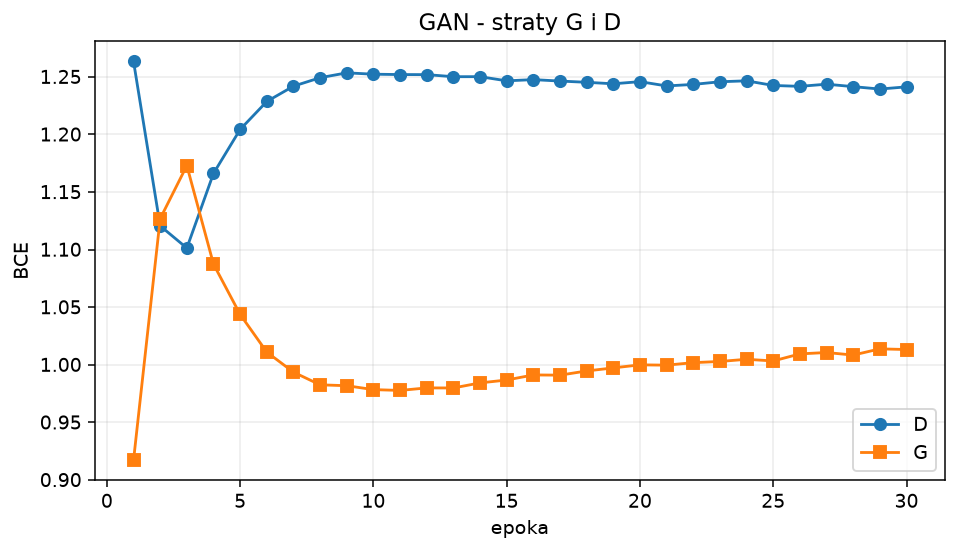

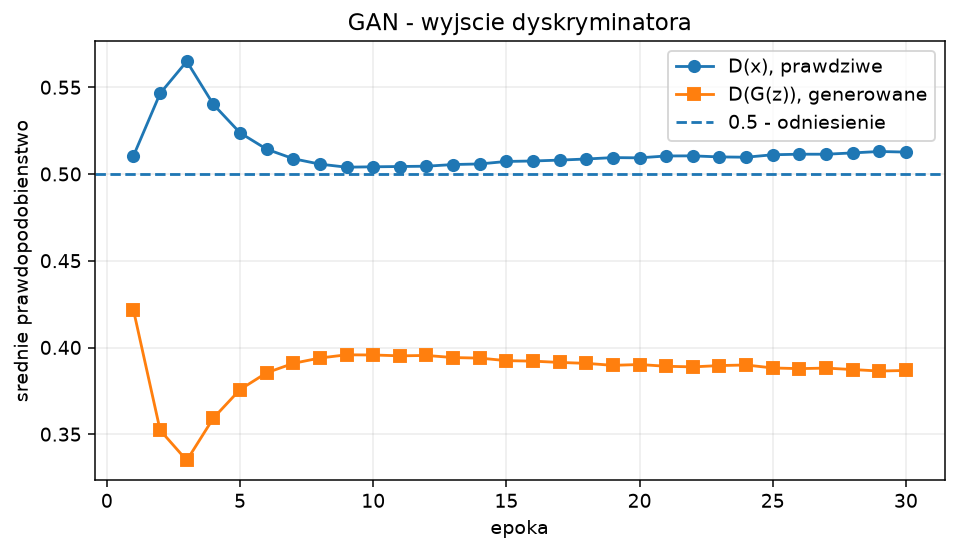

In [19]:
h = hist_gan.history
fig, ax = plt.subplots(figsize=(7.2,4.2))
ep = np.arange(1,len(h['d_loss'])+1)
ax.plot(ep,h['d_loss'],'o-',label='D'); ax.plot(ep,h['g_loss'],'s-',label='G')
ax.set(xlabel='epoka',ylabel='BCE',title='GAN - straty G i D'); ax.legend(); ax.grid(alpha=.25)
fig.tight_layout(); rt.figure(fig,'gan_straty')
fig, ax = plt.subplots(figsize=(7.2,4.2))
ax.plot(ep,h['D_real'],'o-',label='D(x), prawdziwe')
ax.plot(ep,h['D_fake'],'s-',label='D(G(z)), generowane')
ax.axhline(.5,ls='--',label='0.5 - odniesienie')
ax.set(xlabel='epoka',ylabel='srednie prawdopodobienstwo',title='GAN - wyjscie dyskryminatora')
ax.legend(); ax.grid(alpha=.25); fig.tight_layout(); rt.figure(fig,'gan_diagnostyki_D')



--- Komorka 36 ---


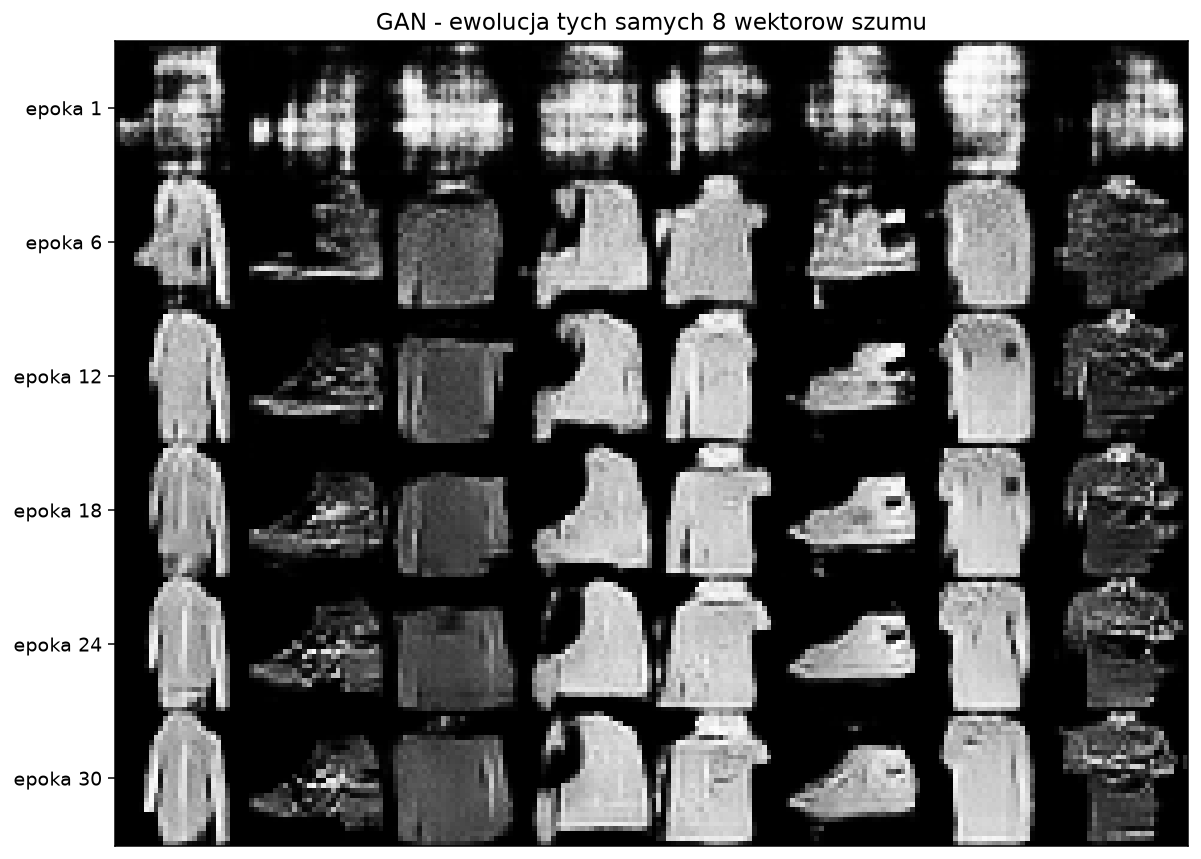

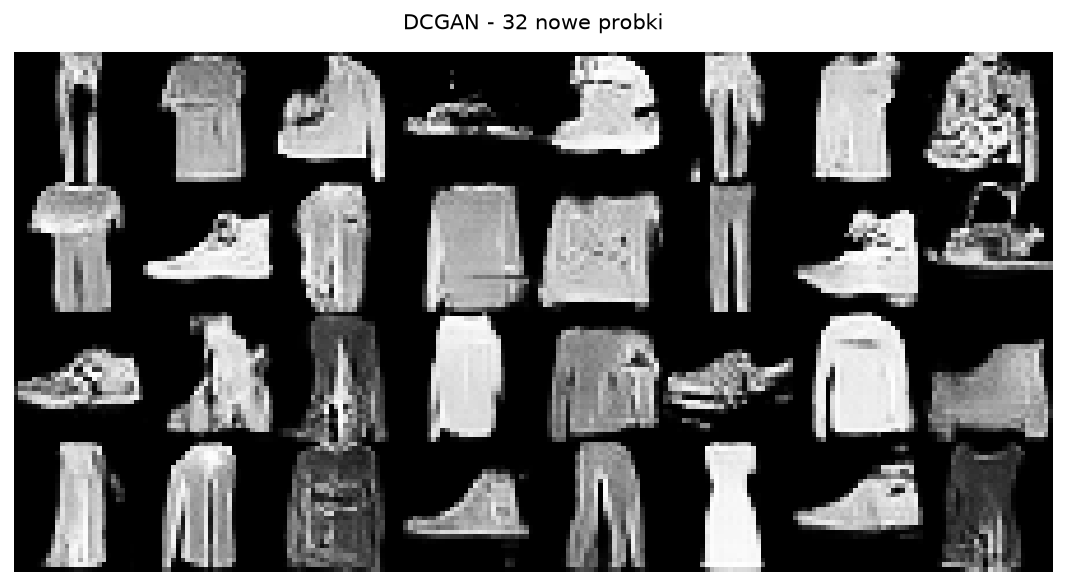

In [20]:
epoki_do_pokazu = sorted(set(np.linspace(0,len(monitor.migawki)-1,min(6,len(monitor.migawki))).astype(int)))
canvas = np.concatenate([np.concatenate([monitor.migawki[e][c,:,:,0] for c in range(8)],axis=1) for e in epoki_do_pokazu],axis=0)
fig, ax = plt.subplots(figsize=(9,1.1*len(epoki_do_pokazu)+.6))
ax.imshow(canvas,cmap='gray',vmin=-1,vmax=1)
ax.set_xticks([]); ax.set_yticks([28*i+13.5 for i in range(len(epoki_do_pokazu))],
                               labels=['epoka '+str(e+1) for e in epoki_do_pokazu])
ax.set_title('GAN - ewolucja tych samych 8 wektorow szumu'); fig.tight_layout()
rt.figure(fig,'gan_ewolucja_probek')
plansza(ops.convert_to_numpy(G(keras.random.normal((32,LATENT_GAN),seed=7),training=False)),
        4,8,'DCGAN - 32 nowe probki',zakres=(-1,1),slug='gan_nowe_probki')


### Zadanie 3.3 - interpolacja w przestrzeni szumu GAN (liniowa i sferyczna)

Przestrzeń $\mathbf{z}$ GAN-a też jest ciągła. Wylosuj dwa wektory $\mathbf{z}_a, \mathbf{z}_b$ i wygeneruj 10 obrazów pośrednich na dwa sposoby:
1. **liniowo:** $\mathbf{z}_t = (1-t)\mathbf{z}_a + t\mathbf{z}_b$,
2. **sferycznie (slerp):** $\mathbf{z}_t = \frac{\sin((1-t)\Omega)}{\sin\Omega}\mathbf{z}_a + \frac{\sin(t\Omega)}{\sin\Omega}\mathbf{z}_b$, gdzie $\cos\Omega = \frac{\mathbf{z}_a\cdot\mathbf{z}_b}{\lVert\mathbf{z}_a\rVert\lVert\mathbf{z}_b\rVert}$.

Dlaczego slerp? W wysokim wymiarze prawie cała masa $\mathcal{N}(0, I)$ leży na "skorupie" o promieniu $\approx\sqrt{d}$. Środek odcinka między dwoma losowymi punktami ma normę ok. $\sqrt{d/2}$ - to obszar, którego generator prawie nie widział podczas treningu. Slerp idzie po skorupie.

Zapisz normy pośrednich wektorów (`normy_lin`, `normy_slerp`) i narysuj je na wykresie oraz oba wiersze obrazów.

**Kryteria sukcesu:** norma interpolacji liniowej "zapada się" w środku (ok. $0.71\sqrt{d}$), slerp utrzymuje ją ok. $\sqrt{d}$.


--- Komorka 38 ---


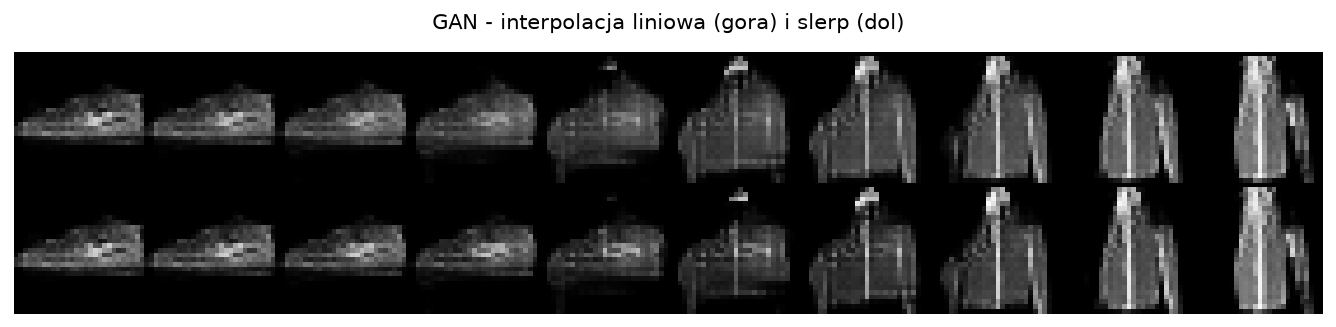

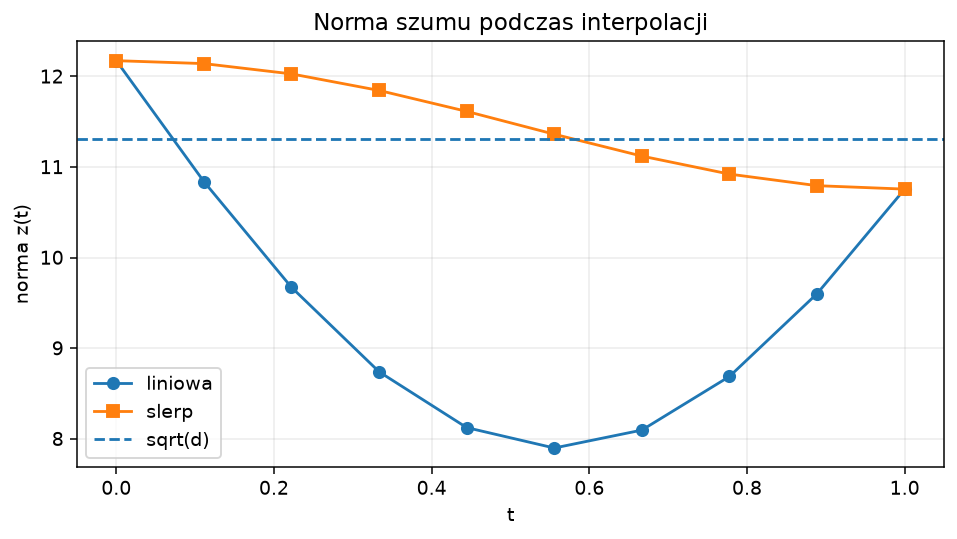

In [21]:
def slerp(za,zb,t):
    za,zb = np.asarray(za,dtype='float64'),np.asarray(zb,dtype='float64')
    norma = np.linalg.norm(za)*np.linalg.norm(zb)
    if norma < 1e-12:
        return (1-t)*za + t*zb
    omega = np.arccos(np.clip(np.dot(za,zb)/norma,-1,1))
    if abs(np.sin(omega)) < 1e-7:
        # Slerp dla wektorow rownoleglych/antyrownoleglych jest zle uwarunkowany.
        return (1-t)*za + t*zb
    return np.sin((1-t)*omega)/np.sin(omega)*za + np.sin(t*omega)/np.sin(omega)*zb

rng = np.random.default_rng(3)
z_a,z_b = rng.normal(size=LATENT_GAN),rng.normal(size=LATENT_GAN)
ts = np.linspace(0,1,10)
z_lin = np.asarray([(1-t)*z_a + t*z_b for t in ts],dtype='float32')
z_slerp = np.asarray([slerp(z_a,z_b,t) for t in ts],dtype='float32')
assert np.allclose(z_slerp[0],z_a) and np.allclose(z_slerp[-1],z_b)
normy_lin, normy_slerp = np.linalg.norm(z_lin,axis=1), np.linalg.norm(z_slerp,axis=1)
ob_lin = ops.convert_to_numpy(G(z_lin,training=False))
ob_slerp = ops.convert_to_numpy(G(z_slerp,training=False))
plansza(np.concatenate([ob_lin,ob_slerp]),2,10,'GAN - interpolacja liniowa (gora) i slerp (dol)',
        zakres=(-1,1),slug='gan_interpolacje')
fig,ax=plt.subplots(figsize=(7.2,4.1))
ax.plot(ts,normy_lin,'o-',label='liniowa'); ax.plot(ts,normy_slerp,'s-',label='slerp')
ax.axhline(np.sqrt(LATENT_GAN),ls='--',label='sqrt(d)')
ax.set(xlabel='t',ylabel='norma z(t)',title='Norma szumu podczas interpolacji')
ax.legend(); ax.grid(alpha=.25); fig.tight_layout(); rt.figure(fig,'gan_normy_interpolacji')
RAPORT['zad_3_3']={'normy_lin':normy_lin,'normy_slerp':normy_slerp,
                  'uwaga':'Losowe konce maja rozne normy, slerp nie musi miec idealnie stalego promienia.'}
RAPORT['testy']['slerp_konce']=True
rt.done('3.3')


### Zadanie 3.4 - czy mamy mode collapse? Pomiar różnorodności klasyfikatorem

Wzrokowa ocena jest subiektywna. Prosty, ilościowy sposób (idea zbliżona do *Inception Score*): wytrenuj klasyfikator Fashion-MNIST i sprawdź, **jak rozkładają się klasy wygenerowanych obrazów**. Zdrowy GAN generuje wszystkie 10 klas mniej więcej po równo; przy mode collapse dominuje kilka klas.

1. Klasyfikator (gotowy kod poniżej) - uruchom i sprawdź dokładność na teście.
2. Wygeneruj `N_GEN` obrazów, sklasyfikuj je, policz histogram klas i **znormalizowaną entropię** rozkładu klas $H = -\frac{1}{\log 10}\sum_c p_c \log p_c$ ($H=1$ - idealnie równo, $H\to0$ - jedna klasa). Zapisz w `entropia_gen`.
3. Policz średnią maksymalną pewność klasyfikatora na próbkach (`pewnosc_gen`) - niska oznacza obrazy "niepodobne do niczego".
4. Porównaj z tymi samymi miarami dla prawdziwych obrazów testowych (`entropia_real`, `pewnosc_real`).

In [22]:
keras.utils.set_random_seed(SEED)
wej=keras.Input(shape=(28,28,1))
h=layers.Conv2D(32,3,activation='relu',padding='same')(wej)
h=layers.MaxPooling2D()(h)
h=layers.Conv2D(64,3,activation='relu',padding='same')(h)
h=layers.MaxPooling2D()(h)
h=layers.Flatten()(h)
cechy=layers.Dense(64,activation='relu',name='cechy')(h)
wyj=layers.Dense(10,activation='softmax')(layers.Dropout(.3)(cechy))
klasyfikator=keras.Model(wej,wyj,name='klasyfikator_fashion')
klasyfikator.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'],jit_compile=False)
options=tf.data.Options(); options.threading.private_threadpool_size=max(1,WATKI)
ds_clf=(tf.data.Dataset.from_tensor_slices((x_fash,y_fash)).shuffle(len(x_fash),seed=SEED)
        .batch(128).with_options(options).prefetch(1))
t0=time.perf_counter()
hist_clf=klasyfikator.fit(ds_clf,epochs=cfg['clf'],verbose=2,callbacks=[KontrolaEpoki('klasyfikator')])
rt.history(hist_clf,'klasyfikator')
clf_eval=klasyfikator.evaluate(x_fash_te,y_fash_te,batch_size=128,return_dict=True,verbose=0)
RAPORT['klasyfikator']={**{k:float(v) for k,v in clf_eval.items()},'czas_s':round(time.perf_counter()-t0,2)}
klasyfikator.save(rt.models/'klasyfikator_fashion.keras')
print('Klasyfikator - test:',RAPORT['klasyfikator'])
if clf_eval['accuracy'] < .8:
    rt.warn('Klasyfikator ma test accuracy < 0.80. Entropie i FID-lite trzeba interpretowac szczegolnie ostroznie.')
rt.save()



--- Komorka 40 ---
Epoch 1/5


469/469 - 12s - 26ms/step - accuracy: 0.7948 - loss: 0.5780
Epoch 2/5


469/469 - 11s - 23ms/step - accuracy: 0.8719 - loss: 0.3616
Epoch 3/5


469/469 - 11s - 23ms/step - accuracy: 0.8906 - loss: 0.3092
Epoch 4/5


469/469 - 11s - 24ms/step - accuracy: 0.9006 - loss: 0.2776
Epoch 5/5


469/469 - 11s - 23ms/step - accuracy: 0.9100 - loss: 0.2488


Klasyfikator - test: {'accuracy': 0.9088000059127808, 'loss': 0.2489895075559616, 'czas_s': 56.99}



--- Komorka 41 ---
   klasa  liczba_gen  udzial_gen  liczba_real_pred  udzial_real_pred
 T-shirt         576      0.1152              1018            0.1018
 spodnie         406      0.0812               991            0.0991
  sweter         359      0.0718               900            0.0900
sukienka         599      0.1198              1052            0.1052
 plaszcz         560      0.1120              1066            0.1066
  sandal         345      0.0690               996            0.0996
 koszula         694      0.1388               980            0.0980
 sneaker         529      0.1058              1042            0.1042
   torba         435      0.0870               986            0.0986
   botek         497      0.0994               969            0.0969


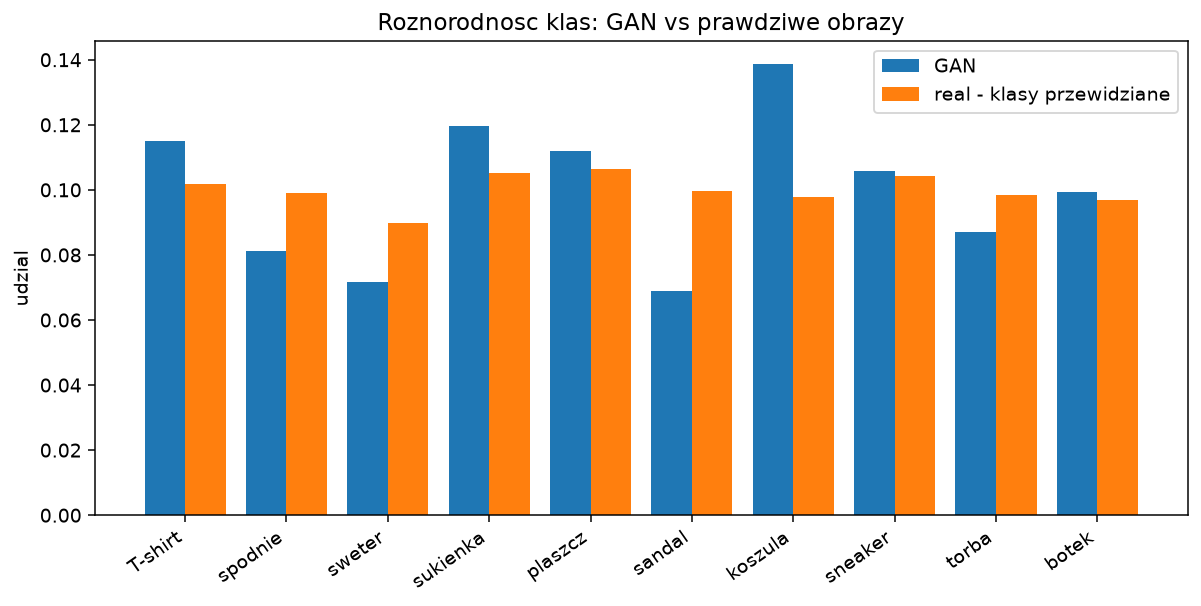

Entropia GAN/real: 0.9899702340086801 0.9995439376913728 | pewnosc: 0.7800750732421875 0.9163368940353394


In [23]:
def entropia_znorm(p):
    p=np.asarray(p,dtype='float64')
    p=p[p>0]
    return float(-(p*np.log(p)).sum()/np.log(10))

z_gen=np.random.default_rng(SEED+100).normal(size=(N_GEN,LATENT_GAN)).astype('float32')
x_gen=G.predict(z_gen,batch_size=128,verbose=0)
p_gen=klasyfikator.predict(x_gen,batch_size=128,verbose=0)
p_real=klasyfikator.predict(x_fash_te,batch_size=128,verbose=0)
# Histogram to twarde klasy argmax, nie srednia softmaxow.
hist_gen=np.bincount(np.argmax(p_gen,axis=1),minlength=10)
hist_real=np.bincount(np.argmax(p_real,axis=1),minlength=10)
entropia_gen=entropia_znorm(hist_gen/hist_gen.sum())
entropia_real=entropia_znorm(hist_real/hist_real.sum())
pewnosc_gen,pewnosc_real=float(p_gen.max(1).mean()),float(p_real.max(1).mean())
assert np.isfinite(p_gen).all() and np.allclose(p_gen.sum(1),1,atol=1e-5)
RAPORT['zad_3_4']={'n_gen':N_GEN,'n_real':len(x_fash_te),'entropia_gen':entropia_gen,
                  'entropia_real':entropia_real,'pewnosc_gen':pewnosc_gen,'pewnosc_real':pewnosc_real,
                  'histogram_gen':hist_gen,'histogram_real_predykcje':hist_real,
                  'uwaga':'Brak automatycznego werdyktu mode collapse. Sprawdz obrazy i jakosc klasyfikatora.'}
rt.table(pd.DataFrame({'klasa':KLASY_FASHION,'liczba_gen':hist_gen,'udzial_gen':hist_gen/N_GEN,
                      'liczba_real_pred':hist_real,'udzial_real_pred':hist_real/len(x_fash_te)}),'roznorodnosc_klas.csv')
fig,ax=plt.subplots(figsize=(9,4.6)); pos=np.arange(10)
ax.bar(pos-.2,hist_gen/N_GEN,width=.4,label='GAN')
ax.bar(pos+.2,hist_real/len(x_fash_te),width=.4,label='real - klasy przewidziane')
ax.set_xticks(pos,labels=KLASY_FASHION,rotation=35,ha='right')
ax.set(ylabel='udzial',title='Roznorodnosc klas: GAN vs prawdziwe obrazy')
ax.legend(); fig.tight_layout(); rt.figure(fig,'gan_histogram_klas')
print('Entropia GAN/real:',entropia_gen,entropia_real,'| pewnosc:',pewnosc_gen,pewnosc_real)
if hist_gen.max()/N_GEN > .5:
    rt.warn('Ponad polowa probek GAN ma te sama przewidywana klase: sprawdz mode collapse i bledy klasyfikatora.')
rt.done('3.4')


### Czy GAN zapamiętał dane treningowe? Test najbliższego sąsiada

Jeśli generator kopiuje obrazy treningowe, każda próbka ma "bliźniaka" w zbiorze uczącym. Dla kilku próbek szukamy najbliższego obrazu treningowego (odległość euklidesowa w przestrzeni cech klasyfikatora - bardziej semantyczna niż piksele) i wyświetlamy pary. Podobne, ale **nie identyczne** pary to dobry znak - model uogólnia.


--- Komorka 43 ---


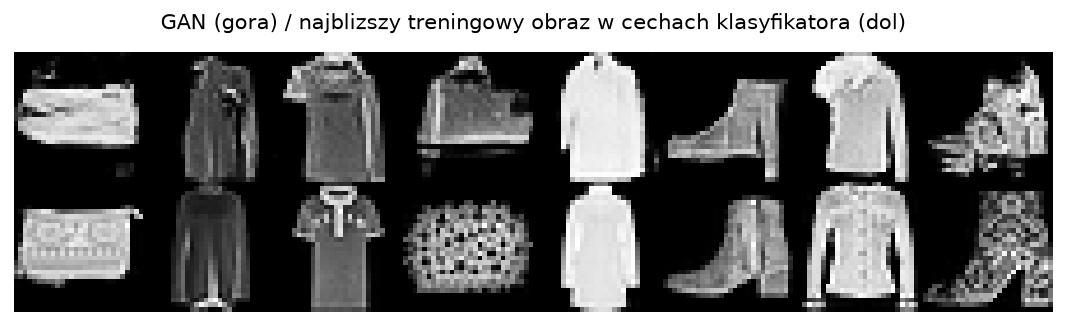

Odleglosci NN: [3.30623913 5.13097954 3.92880416 5.3483963  3.37164354 5.94049358
 5.05594158 3.89169121]


In [24]:
from sklearn.neighbors import NearestNeighbors
ekstr_nn=keras.Model(klasyfikator.input,klasyfikator.get_layer('cechy').output)
f_tr=ekstr_nn.predict(x_fash,batch_size=128,verbose=0)
x_pr=ops.convert_to_numpy(G(keras.random.normal((8,LATENT_GAN),seed=21),training=False))
odl,idx=NearestNeighbors(n_neighbors=1).fit(f_tr).kneighbors(ekstr_nn.predict(x_pr,verbose=0))
plansza(np.concatenate([x_pr,x_fash[idx[:,0]]]),2,8,
        'GAN (gora) / najblizszy treningowy obraz w cechach klasyfikatora (dol)',
        zakres=(-1,1),slug='gan_najblizsi_sasiedzi')
RAPORT['sasiedzi']={'odleglosci':odl[:,0],'indeksy_train':idx[:,0],
                   'uwaga':'8 par nie dowodzi braku zapamietywania. Odleglosc w cechach != identycznosc pikseli.'}
print('Odleglosci NN:',odl[:,0]); rt.save()


### Mode collapse i niestabilność - jak rozpoznać i co robić

| Objaw | Co widać | Typowe leki |
|---|---|---|
| Mode collapse | próbki prawie identyczne, niska entropia klas | minibatch discrimination, unrolled GAN, WGAN-GP, mniejsze lr G, restart |
| D wygrywa | `d_loss` -> 0, `D_fake` -> 0, `g_loss` rośnie | label smoothing, Dropout / szum w D, mniejsze lr D, mniej kroków D |
| G "oszukuje" słabego D | `D_fake` > 0.5 długo, obrazy słabe | większa pojemność D, więcej kroków D |
| Oscylacje | jakość próbek rośnie i spada | mniejsze lr, Adam z $\beta_1 = 0.5$, EMA wag G, zapis checkpointów i wybór najlepszego |

Zaawansowane warianty (W5): **WGAN / WGAN-GP** (odległość Wassersteina zamiast BCE - stabilniejsze gradienty), **spectral normalization** w D, **conditional GAN** (generowanie zadanej klasy), **StyleGAN**. Miara jakości: **FID** - odległość Frécheta między rozkładami cech (zwykle z sieci Inception) prawdziwych i wygenerowanych obrazów; im niższy, tym lepiej.

## 4. *(Opcjonalnie)* Ten sam GAN w PyTorch - wersja skrócona

Ta sekcja jest dla chętnych lub do domu. Pokazuje, że GAN to w istocie **dwie przeplatające się pętle optymalizacji**, które w PyTorch piszemy jawnie (W3). Architektura jest odpowiednikiem naszego DCGAN; różnice notacyjne:
- obrazy w formacie **NCHW** `(batch, 1, 28, 28)` (Keras: NHWC),
- `nn.ConvTranspose2d(k=4, s=2, p=1)` podwaja rozdzielczość: $H_{out} = (H-1)\cdot2 - 2\cdot1 + 4 = 2H$,
- `nn.BCEWithLogitsLoss` = sigmoid + BCE (odpowiednik `from_logits=True`),
- **`fake.detach()`** w kroku D - odcinamy graf, żeby gradient straty D nie płynął do G,
- `opt.zero_grad()` przed każdym `backward()`, bo PyTorch domyślnie **akumuluje** gradienty.

In [25]:
if PYTORCH:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    torch.manual_seed(SEED)
    torch.set_num_threads(WATKI)
    device=torch.device('cpu')
    # Dane te same co w Keras; jedynie NHWC -> NCHW.
    ds_t=TensorDataset(torch.from_numpy(np.transpose(x_fash,(0,3,1,2)).copy()),
                       torch.from_numpy(y_fash.astype('int64')))
    loader=DataLoader(ds_t,batch_size=128,shuffle=True,drop_last=True,num_workers=0,
                      generator=torch.Generator().manual_seed(SEED))
    LAT_T=64
    class GenT(nn.Module):
        def __init__(self,latent=64):
            super().__init__()
            self.fc=nn.Sequential(nn.Linear(latent,128*7*7,bias=False),nn.BatchNorm1d(128*7*7),nn.LeakyReLU(.2))
            self.conv=nn.Sequential(nn.ConvTranspose2d(128,64,4,2,1,bias=False),nn.BatchNorm2d(64),
                                    nn.LeakyReLU(.2),nn.ConvTranspose2d(64,1,4,2,1),nn.Tanh())
        def forward(self,z):
            return self.conv(self.fc(z).view(-1,128,7,7))
    class DisT(nn.Module):
        def __init__(self):
            super().__init__()
            self.net=nn.Sequential(nn.Conv2d(1,64,4,2,1),nn.LeakyReLU(.2),nn.Conv2d(64,128,4,2,1),
                                   nn.LeakyReLU(.2),nn.Flatten(),nn.Dropout(.3),nn.Linear(128*7*7,1))
        def forward(self,x):
            return self.net(x)
    G_t,D_t=GenT().to(device),DisT().to(device)
    opt_G=torch.optim.Adam(G_t.parameters(),lr=2e-4,betas=(.5,.999))
    opt_D=torch.optim.Adam(D_t.parameters(),lr=2e-4,betas=(.5,.999))
    kryterium=nn.BCEWithLogitsLoss()
    print('PyTorch:',torch.__version__,'| CPU | latent=',LAT_T)
else:
    print('Sekcja 4 opcjonalna: pomijam. Do wlaczenia sluzy --pytorch.')



--- Komorka 46 ---
Sekcja 4 opcjonalna: pomijam. Do wlaczenia sluzy --pytorch.


### Zadanie 4.1 *(opcjonalne)* - pętla treningowa GAN w PyTorch

Uzupełnij ciało pętli po batchach:
1. **Krok D:** `fake = G_t(z)`; `loss_D = kryterium(D_t(real), 0.9·jedynki) + kryterium(D_t(fake.detach()), zera)`; `opt_D.zero_grad()`, `loss_D.backward()`, `opt_D.step()`.
2. **Krok G:** `loss_G = kryterium(D_t(fake), jedynki)`; `opt_G.zero_grad()`, `loss_G.backward()`, `opt_G.step()`.
3. Dopisz `loss_D.item()` i `loss_G.item()` do list `straty_D`, `straty_G`.

**Kryteria sukcesu:** straty w podobnym zakresie jak w Keras; po `EPOKI_TORCH` epokach (pełny tryb) widać rozpoznawalne ubrania.

**Pytanie:** co by się stało bez `.detach()`? (Podpowiedź: `loss_D.backward()` policzyłby gradienty także dla G i zużył graf obliczeniowy - drugi `backward` dla G zgłosiłby błąd lub G uczyłby się w złym kierunku przy kolejnym kroku.)

In [26]:
if PYTORCH:
    straty_D,straty_G=[],[]
    torch_epochs=[]
    z_staly=torch.randn(16,LAT_T,device=device)
    t0=time.perf_counter()
    for epoka in range(EPOKI_TORCH):
        G_t.train(); D_t.train(); te=time.perf_counter()
        ld_epoch,lg_epoch=[],[]
        for real,_ in loader:
            real=real.to(device); b=real.size(0)
            jedynki,zera=torch.ones(b,1,device=device),torch.zeros(b,1,device=device)
            z=torch.randn(b,LAT_T,device=device)
            fake=G_t(z)
            opt_D.zero_grad(set_to_none=True)
            loss_D=kryterium(D_t(real),.9*jedynki)+kryterium(D_t(fake.detach()),zera)
            if not bool(torch.isfinite(loss_D)):
                raise FloatingPointError('PyTorch D: NaN/inf')
            loss_D.backward(); opt_D.step()
            # Nie zmieniamy wag D krokiem G; graf przez D nadal prowadzi do fake.
            for p in D_t.parameters(): p.requires_grad_(False)
            opt_G.zero_grad(set_to_none=True)
            loss_G=kryterium(D_t(fake),jedynki)
            if not bool(torch.isfinite(loss_G)):
                raise FloatingPointError('PyTorch G: NaN/inf')
            loss_G.backward(); opt_G.step()
            for p in D_t.parameters(): p.requires_grad_(True)
            ld,lg=float(loss_D.detach()),float(loss_G.detach())
            straty_D.append(ld); straty_G.append(lg); ld_epoch.append(ld); lg_epoch.append(lg)
        torch_epochs.append({'epoka':epoka+1,'d_loss':float(np.mean(ld_epoch)),
                             'g_loss':float(np.mean(lg_epoch)), 'czas_s':time.perf_counter()-te})
        print('PyTorch epoka:',torch_epochs[-1],flush=True)
        torch.save({'G':G_t.state_dict(),'D':D_t.state_dict(),'opt_G':opt_G.state_dict(),
                    'opt_D':opt_D.state_dict(),'epoka':epoka+1},rt.models/'gan_torch_ostatni.pt')
    RAPORT['zad_4_1']={'czas_s':round(time.perf_counter()-t0,2),'epoki':EPOKI_TORCH,
                      'latent':LAT_T,'batch_size':128,'ostatnie':torch_epochs[-1],
                      'uwaga':'Nie jest to benchmark bibliotek 1:1: inne latent/budzet/inicjalizacja.'}
    RAPORT['opcjonalne']['pytorch']='wykonano'
    rt.table(pd.DataFrame(torch_epochs),'gan_pytorch_epoki.csv'); rt.done('4.1')



--- Komorka 48 ---


In [27]:
if PYTORCH:
    G_t.eval()
    with torch.no_grad():
        probki_t=G_t(z_staly).cpu().numpy().transpose(0,2,3,1)
    fig,ax=plt.subplots(figsize=(8,4))
    ax.plot(straty_D,label='D',alpha=.7);ax.plot(straty_G,label='G',alpha=.7)
    ax.set(xlabel='krok (batch)',ylabel='BCE',title='PyTorch GAN - straty');ax.legend()
    fig.tight_layout();rt.figure(fig,'pytorch_gan_straty')
    plansza(probki_t,2,8,'PyTorch DCGAN - ustalony szum',zakres=(-1,1),slug='pytorch_gan_probki')



--- Komorka 49 ---


## 5. Dalej niż GAN: modele dyfuzyjne i etyka (dyskusja, ok. 10 min)

**Modele dyfuzyjne (W5, zarys).** Proces "w przód" stopniowo dodaje szum gaussowski do obrazu przez $T$ kroków, aż powstanie czysty szum. Sieć (zwykle U-Net) uczy się **odwracać jeden krok** - przewidywać dodany szum $\boldsymbol\epsilon_\theta(\mathbf{x}_t, t)$, strata to proste MSE. Generowanie = start z szumu i $T$ kroków odszumiania. Związki z naszymi zajęciami:
- to uogólnienie **autoenkodera odszumiającego** z Lab 6 na wiele poziomów szumu,
- formalnie to hierarchiczny **VAE** z ustalonym enkoderem (procesem zaszumiania),
- w porównaniu z GAN: trening stabilny (jedna strata MSE, brak gry), wysoka różnorodność (brak mode collapse), ale wolne próbkowanie (wiele kroków).

**Etyka (UGŁ_K01).** Modele generatywne umożliwiają tworzenie **deepfake'ów** (podszywanie się pod osoby, dezinformacja, nadużycia wizerunku), mogą odtwarzać dane treningowe (prywatność, prawa autorskie) i powielać uprzedzenia obecne w danych. Odpowiedzi: znakowanie treści (watermarking, C2PA), detektory, przepisy (AI Act w UE - obowiązek oznaczania treści syntetycznych), dokumentowanie zbiorów i modeli.

**Pytania do dyskusji:**
1. Jak sprawdzić, czy nasz GAN nie "zapamiętał" obrazów treningowych? (wskazówka: najbliższy sąsiad w zbiorze treningowym)
2. Czy publikacja wytrenowanego generatora twarzy powinna wymagać ograniczeń? Jakich?

## 6. Sprawozdanie końcowe z laboratorium - instrukcja

Zgodnie z kartą przedmiotu ocena z laboratorium obejmuje **aktywność na zajęciach, wykonanie ćwiczeń i przesłanie sprawozdania podsumowującego po ostatnich zajęciach**. Ocena końcowa z przedmiotu = 60% kolokwium + 40% laboratorium (aktywność + sprawozdanie); obie części muszą być zaliczone pozytywnie.

### Termin i forma
- **Jedno sprawozdanie indywidualne** w formacie **PDF** (zalecane 10-15 stron bez załączników), przesłane w terminie i kanałem podanym przez prowadzącą.
- Do sprawozdania dołącz **link do notebooka Colab** z mini-projektem (udostępnienie "każdy, kto ma link - przeglądający") albo plik `.ipynb` **z zapisanymi wynikami komórek**.
- Nazwa pliku: `UG_Sprawozdanie_Nazwisko_Imie_nrIndeksu.pdf`.

### Wymagana struktura
1. **Strona tytułowa:** imię i nazwisko, nr indeksu, kierunek i semestr, nazwa kursu, prowadząca, data.
2. **Wybrane wyniki z Lab 3-7** (ok. 1-2 strony na laboratorium). W każdym laboratorium sekcja "Do sprawozdania końcowego" mówi, co pokazać. Każdy wykres musi mieć tytuł, opisane osie, legendę i **1-3 zdania interpretacji** (co widać, dlaczego, co z tego wynika).
3. **Mini-projekt - własny eksperyment** (najważniejsza część, ok. 4-6 stron):
   - **problem i zbiór danych** - wyłącznie zbiory używane na kursie (`keras.datasets`: MNIST, Fashion-MNIST, CIFAR-10; `sklearn.datasets`; `torchvision` MNIST/FashionMNIST) lub inne publiczne po uzgodnieniu z prowadzącą,
   - **hipoteza** sformułowana przed eksperymentem, w postaci sprawdzalnej, np. *"Autoenkoder konwolucyjny wykryje anomalie (klasa 'sandał') w Fashion-MNIST z wyższym ROC-AUC niż autoenkoder gęsty o tej samej liczbie parametrów"* (**UGŁ_U01**),
   - **metodyka** - architektura(y), hiperparametry, podział danych, metryki, baseline (np. model klasyczny lub prostszy model sieciowy), liczba powtórzeń (seedy),
   - **wyniki** - tabela i wykresy, najlepiej średnia ± odchylenie standardowe z co najmniej 3 uruchomień,
   - **weryfikacja hipotezy** - potwierdzona / odrzucona / częściowo, z uzasadnieniem liczbowym,
   - **propozycja usprawnienia** opartego na istniejących bibliotekach (np. inna architektura, regularyzacja, augmentacja, transfer learning, tuning KerasTuner/Optuna), **najlepiej sprawdzona eksperymentalnie** (**UGŁ_U02**).
4. **Wnioski i ograniczenia** (0,5-1 strona): co się udało, czego nie wiemy, co zrobiłbyś dalej.
5. **Bibliografia:** co najmniej 3 pozycje, w tym min. 1 z literatury przedmiotu i min. 1 artykuł naukowy lub dokumentacja (keras.io, pytorch.org) - **UGŁ_K01**.
6. **Oświadczenie o samodzielności** i informacja o użyciu narzędzi AI (do czego, w jakim zakresie). Kod i tekst muszą być rozumiane przez autora - prowadząca może poprosić o krótkie omówienie.

### Przykładowe tematy mini-projektu
- VAE vs AE vs PCA jako ekstraktor cech dla k-means na Fashion-MNIST (ARI/NMI).
- Wpływ $\beta$ i wymiaru latentu VAE na jakość rekonstrukcji i różnorodność próbek.
- DCGAN vs DCGAN z innymi technikami stabilizacji (label smoothing, spectral norm, różne lr D i G) - porównanie entropii klas / FID-lite.
- Transfer learning vs CNN od zera na podzbiorach CIFAR-10 różnej wielkości (krzywa uczenia w funkcji liczby danych).
- Sieć MLP (PyTorch) vs HistGradientBoosting na `fetch_california_housing` lub `load_breast_cancer` z walidacją krzyżową i analizą wycieku danych.

### Checklista przed wysłaniem sprawozdania

**Forma**
- [ ] PDF z poprawną nazwą pliku, strona tytułowa kompletna
- [ ] link do notebooka Colab działa (sprawdzone w trybie incognito) lub dołączony `.ipynb` z wynikami
- [ ] notebook wykonuje się od początku do końca (Środowisko wykonawcze -> Uruchom wszystko) bez błędów
- [ ] seedy ustawione, wersje bibliotek podane (komórka poniżej)

**Treść z Lab 3-7**
- [ ] z każdego laboratorium 3-7 co najmniej jeden wynik zgodny z sekcją "Do sprawozdania końcowego"
- [ ] wszystkie wykresy mają tytuł, opisy osi, legendę i interpretację w tekście
- [ ] liczby w tabelach mają jednostki / nazwy metryk i rozsądną liczbę cyfr znaczących

**Mini-projekt**
- [ ] hipoteza sformułowana wprost, **przed** opisem wyników
- [ ] jest baseline i uczciwe porównanie (ten sam podział danych, podobny budżet treningu)
- [ ] brak wycieku danych: skalowanie / PCA / wybór progu dopasowane tylko na zbiorze treningowym (walidacyjnym)
- [ ] zbiór testowy użyty tylko do końcowej oceny, nie do wyboru hiperparametrów
- [ ] wyniki z kilku uruchomień (średnia ± odch. std.) lub uzasadnienie, dlaczego jedno
- [ ] jasna odpowiedź: hipoteza potwierdzona / odrzucona / częściowo - z liczbami
- [ ] propozycja usprawnienia (UGŁ_U02), najlepiej sprawdzona eksperymentalnie

**Na koniec**
- [ ] wnioski i ograniczenia
- [ ] bibliografia (min. 3 pozycje, cytowania w tekście)
- [ ] oświadczenie o samodzielności i o użyciu narzędzi AI

In [28]:
RAPORT['biblioteki']['backend_keras']=keras.backend.backend()
print(json.dumps(RAPORT['biblioteki'],indent=2,ensure_ascii=False))
print('Seed:',SEED,'| profil:',PROFIL,'| watki CPU:',WATKI)
rt.save()



--- Komorka 53 ---
{
  "python": "3.11.9",
  "tensorflow": "2.20.0",
  "keras": "3.15.1",
  "numpy": "2.2.6",
  "pandas": "2.3.3",
  "scipy": "1.17.1",
  "scikit-learn": "1.9.1",
  "matplotlib": "3.11.2",
  "backend_keras": "tensorflow"
}
Seed: 42 | profil: full | watki CPU: 4


In [29]:
def raport_powtorzen(wyniki,nazwa='metryka'):
    w=np.asarray(wyniki,dtype=float)
    if not len(w) or not np.isfinite(w).all():
        raise ValueError('Brak poprawnych wynikow do podsumowania')
    if len(w)==1:
        return f'{nazwa} = {w[0]:.4f} (n=1; odchylenie standardowe nieoszacowane)'
    return f'{nazwa} = {w.mean():.4f} +/- {w.std(ddof=1):.4f} (n={len(w)})'
print('W tym przebiegu jest jedno ziarno. Nie wpisujemy fikcyjnych powtorzen do raportu.')



--- Komorka 54 ---
W tym przebiegu jest jedno ziarno. Nie wpisujemy fikcyjnych powtorzen do raportu.


## Pytania kontrolne

1. Jakie dwa składniki ma strata VAE i co by się stało, gdyby usunąć każdy z nich?
2. Na czym polega trik reparametryzacji i dlaczego jest potrzebny?
3. Dlaczego enkoder VAE zwraca $\log\sigma^2$, a nie $\sigma$?
4. Dlaczego próbki z VAE są zwykle bardziej rozmyte niż z GAN?
5. Zapisz funkcję celu minimax GAN. Czym jest *non-saturating loss* generatora i dlaczego się go używa?
6. Dlaczego w kroku dyskryminatora w PyTorch używamy `fake.detach()`, a w Keras liczymy gradient tylko po `discriminator.trainable_weights`?
7. Czym jest mode collapse i jak można go wykryć ilościowo? Jakie ograniczenia ma miara oparta na rozkładzie klas?
8. Dlaczego wartości strat G i D nie są dobrą miarą jakości wygenerowanych obrazów? Co stosujemy zamiast nich?

## Podsumowanie - co warto zapamiętać

**Z tego laboratorium**
- **VAE** = AE z probabilistycznym enkoderem; strata = rekonstrukcja (suma po pikselach) + $\beta\cdot$KL; **trik reparametryzacji** $z = \mu + \sigma\epsilon$; przestrzeń latentna jest regularna - można z niej losować i interpolować.
- $\beta$ steruje kompromisem: regularność latentu vs jakość rekonstrukcji.
- **GAN** = gra G vs D; trenujemy naprzemiennie, z gradientami tylko po wagach właściwej sieci; G używa *non-saturating loss*; zasady DCGAN (stride, BN w G, LeakyReLU w D, tanh, Adam 2e-4/0.5).
- **Straty GAN nie mierzą jakości** - monitorujemy próbki z ustalonego szumu, $D(x)$, $D(G(z))$, różnorodność (entropia klas, FID).
- W Keras 3 własny `train_step`: `tf.GradientTape`, `keras.ops`, `keras.random` z `SeedGenerator`, metryki-śledzące zwracane przez właściwość `metrics`, `super().compile()`.
- W PyTorch: `zero_grad -> backward -> step`, `fake.detach()` w kroku D, `eval()` + `no_grad()` przy generowaniu.

**Z całego kursu (W1-W5, L1-L7)**
- DL = modelowanie (architektura) + optymalizacja (strata, gradient, optymalizator) - od regresji liniowej z gradientem liczonym ręcznie (L1) do modeli generatywnych (L7).
- Komponenty: warstwy gęste, splotowe, pooling, transponowane, normalizacja, Dropout, residua - dobór do danych i zadania.
- Rzetelność: poprawny podział danych, brak wycieku, baseline, kilka uruchomień, właściwe metryki.
- Uczenie nienadzorowane: PCA/SVD/LDA, autoenkodery, klasteryzacja w latencie, VAE, GAN, dyfuzja.

## Do sprawozdania końcowego

Z tego laboratorium umieść w sprawozdaniu:
1. Przestrzeń latentną VAE (wykres `z_mean`) i siatkę wygenerowanych cyfr z interpretacją (czy przestrzeń jest regularna? gdzie leżą które cyfry?).
2. Wyniki eksperymentu z $\beta$ (Zadanie 2.4) - tabela + **hipoteza i jej weryfikacja**.
3. Krzywe strat GAN, wykres $D(x)$ / $D(G(z))$ oraz planszę ewolucji próbek po epokach - z komentarzem, dlaczego straty nie mówią o jakości.
4. Ocenę różnorodności (entropia klas, pewność klasyfikatora) i odpowiedź: czy wystąpił mode collapse?
5. *(Opcjonalnie)* porównanie implementacji Keras i PyTorch (czas epoki, wygląd próbek) lub wynik zadania dodatkowego (FID-lite) - dobry punkt wyjścia do mini-projektu.

## Zadanie dodatkowe (dla chętnych) - "FID-lite": odległość Frécheta w przestrzeni cech klasyfikatora

**FID** (Heusel i in., 2017) modeluje cechy obrazów prawdziwych i wygenerowanych jako rozkłady normalne $\mathcal{N}(\mu_r, \Sigma_r)$ i $\mathcal{N}(\mu_g, \Sigma_g)$ i liczy odległość Frécheta:
$$\text{FD} = \lVert\mu_r - \mu_g\rVert^2 + \operatorname{Tr}\left(\Sigma_r + \Sigma_g - 2(\Sigma_r\Sigma_g)^{1/2}\right).$$
Oryginalny FID używa cech sieci Inception-v3 (2048 wymiarów). My użyjemy 64-wymiarowej warstwy `cechy` naszego klasyfikatora Fashion-MNIST - wartości nie są porównywalne z FID z literatury, ale ranking modeli ma sens.

1. Zbuduj model `ekstraktor` zwracający wyjście warstwy `cechy`.
2. Napisz `frechet(f1, f2)` (użyj `scipy.linalg.sqrtm`, odrzuć część urojoną).
3. Policz FD dla: (a) dwóch rozłącznych połówek prawdziwych obrazów testowych (punkt odniesienia ~0), (b) próbek z wytrenowanego `G`, (c) próbek z **niewytrenowanego** generatora, (d) próbek z generatora PyTorch (jeśli trenowałeś). Zapisz w słowniku `fd`.

**Kryteria sukcesu:** FD(a) < FD(b) << FD(c).


--- Komorka 59 ---
      porownanie         FD  n_na_zbior
real_A_vs_real_B   0.268874        5000
       GAN_Keras  15.376386        5000
  G_nietrenowany 270.175729        5000


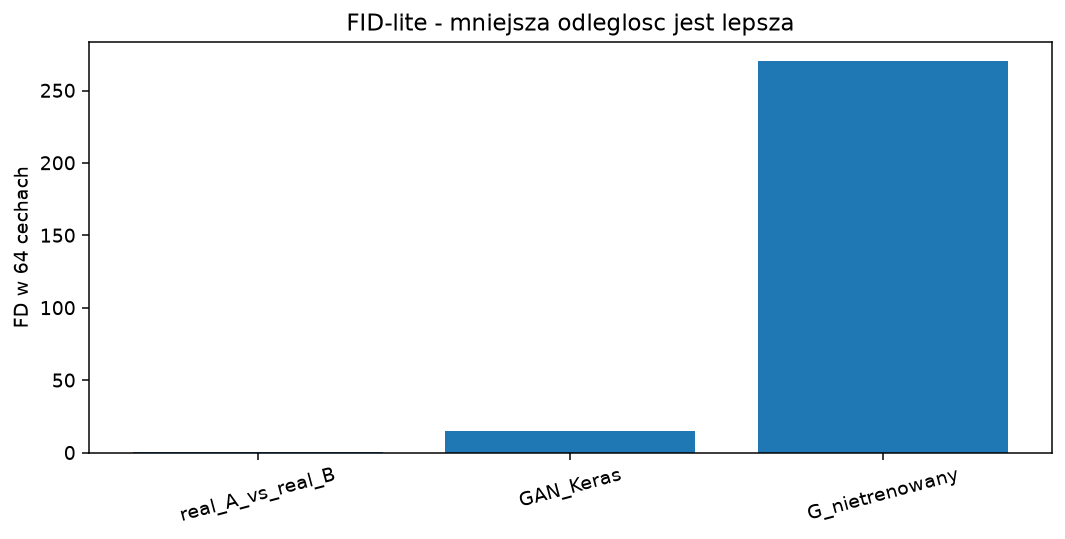

In [30]:
if BONUS:
    from scipy.linalg import sqrtm
    def frechet(f1,f2):
        f1,f2=np.asarray(f1,dtype='float64'),np.asarray(f2,dtype='float64')
        if f1.ndim!=2 or f2.ndim!=2 or f1.shape[1]!=f2.shape[1] or min(len(f1),len(f2))<2:
            raise ValueError('FD wymaga dwoch macierzy cech z co najmniej 2 obrazami')
        if not np.isfinite(f1).all() or not np.isfinite(f2).all():
            raise ValueError('FD: NaN/inf w cechach')
        mu1,mu2=f1.mean(0),f2.mean(0)
        c1,c2=np.cov(f1,rowvar=False),np.cov(f2,rowvar=False)
        root=sqrtm(c1@c2)
        # sqrtm moze dac drobny blad urojony dla numerycznie osobliwej kowariancji.
        if np.iscomplexobj(root):
            rel_im=float(np.linalg.norm(root.imag)/max(1.,np.linalg.norm(root.real)))
            if rel_im>1e-5:
                raise FloatingPointError(f'FD: za duza czesc urojona sqrtm ({rel_im:g})')
            root=root.real
        raw=float(np.sum((mu1-mu2)**2)+np.trace(c1+c2-2*root))
        scale=max(1.,float(np.trace(c1+c2)))
        if not np.isfinite(raw) or raw < -1e-6*scale:
            raise FloatingPointError(f'FD: wynik {raw}')
        return max(0.,raw)
    probe=np.random.default_rng(21).normal(size=(100,6))
    assert frechet(probe,probe)<1e-6
    RAPORT['testy']['frechet_tozsamosc']=True
    ekstraktor=keras.Model(klasyfikator.input,klasyfikator.get_layer('cechy').output)
    # Ta sama liczba obrazow w kazdym porownaniu, real A i B sa rozlaczne.
    n_fd=min(N_GEN,len(x_fash_te)//2)
    idx_fd=np.random.default_rng(SEED+200).permutation(len(x_fash_te))
    f_real_a=ekstraktor.predict(x_fash_te[idx_fd[:n_fd]],batch_size=128,verbose=0)
    f_real_b=ekstraktor.predict(x_fash_te[idx_fd[n_fd:2*n_fd]],batch_size=128,verbose=0)
    f_gen=ekstraktor.predict(x_gen[:n_fd],batch_size=128,verbose=0)
    keras.utils.set_random_seed(SEED+201)
    G_losowy=zbuduj_generator()
    x_random=G_losowy.predict(z_gen[:n_fd],batch_size=128,verbose=0)
    f_random=ekstraktor.predict(x_random,batch_size=128,verbose=0)
    fd={'real_A_vs_real_B':frechet(f_real_a,f_real_b),
        'GAN_Keras':frechet(f_real_a,f_gen),'G_nietrenowany':frechet(f_real_a,f_random)}
    if PYTORCH:
        G_t.eval()
        out=[]; rng_t=torch.Generator().manual_seed(SEED+202)
        with torch.no_grad():
            for start in range(0,n_fd,128):
                zt=torch.randn(min(128,n_fd-start),LAT_T,generator=rng_t)
                out.append(G_t(zt.to(device)).cpu().numpy().transpose(0,2,3,1))
        f_t=ekstraktor.predict(np.concatenate(out),batch_size=128,verbose=0)
        fd['GAN_PyTorch']=frechet(f_real_a,f_t)
    RAPORT['bonus_fid_lite']={'odleglosci':fd,'liczba_obrazow_na_zbior':n_fd,
                             'cechy':64,'uwaga':'FID-lite, nie oryginalny Inception FID. Brak porownywalnosci z literatura.'}
    RAPORT['opcjonalne']['fid_lite']='wykonano'
    rt.table(pd.DataFrame({'porownanie':list(fd),'FD':list(fd.values()),'n_na_zbior':n_fd}),'fid_lite.csv')
    if not fd['real_A_vs_real_B'] < fd['GAN_Keras'] < fd['G_nietrenowany']:
        rt.warn('Ranking FID-lite nie spelnia oczekiwanego real-real < GAN < losowy. Zachowujemy wynik; sprawdz obrazy.')
    fig,ax=plt.subplots(figsize=(8,4.1))
    ax.bar(list(fd),list(fd.values()))
    ax.set(ylabel='FD w 64 cechach',title='FID-lite - mniejsza odleglosc jest lepsza')
    ax.tick_params(axis='x',rotation=15)
    fig.tight_layout();rt.figure(fig,'fid_lite')
    rt.done('bonus_fid_lite')
else:
    print('FID-lite pominiete. Do wlaczenia: --bonus.')


## Zapis podsumowania lokalnego


In [31]:
wnioski=[
    'LAB07 - wyniki z lokalnego przebiegu', f'Profil: {PROFIL}; seed: {SEED}',
    f"VAE: test rec_loss={RAPORT['zad_2_2']['ocena_test']['rec_loss']:.3f}, KL={RAPORT['zad_2_2']['ocena_test']['kl_loss']:.3f}.",
    f'Eksperyment beta: {werdykt_beta}; pelna tabela w porownanie_beta.csv.',
    f'GAN: {EPOKI_GAN} epok; straty nie sa samodzielna miara jakosci obrazow.',
    f'Klasyfikator Fashion test accuracy={clf_eval["accuracy"]:.4f}.',
    f'Entropia klas GAN={entropia_gen:.4f}, real={entropia_real:.4f}.',
    f'Srednia pewnosc GAN={pewnosc_gen:.4f}, real={pewnosc_real:.4f}.',
    'Mode collapse: wymaga oceny plansz wraz z histogramem; brak automatycznego potwierdzenia/wykluczenia.',
    'Najblizsi sasiedzi: podobienstwo 8 par nie rozstrzyga, czy model zapamietal trening.',
    'VAE walidowano na 10% puli treningowej; oficjalny test wykorzystano do oceny i ilustracji.',
    'Usprawnienie do przyszlego mini-projektu: zmniejszenie lr D przy tym samym budzecie GAN, min. 3 seedy; NIE wykonano tutaj.',
]
if BONUS:
    wnioski.append('FID-lite: '+str(RAPORT['bonus_fid_lite']['odleglosci']))
wnioski.append('Ostrzezenia: '+('; '.join(RAPORT['ostrzezenia']) or 'brak technicznych; obrazy nadal wymagaja oceny'))
(rt.root/'wnioski.txt').write_text('\n'.join(wnioski)+'\n',encoding='utf-8')
RAPORT['status']='UKONCZONO_TEST' if PROFIL!='full' else 'UKONCZONO_DO_OCENY_WYNIKOW'
RAPORT['bonus_wykonany']=BONUS
RAPORT['pytorch_wykonany']=PYTORCH
RAPORT['liczba_wykresow']=len(RAPORT['wykresy'])
rt.done('podsumowanie')
print('\nKONIEC:',RAPORT['status'])
print('Wyniki:',rt.root)
print('Wykresy:',RAPORT['liczba_wykresow'])
if TRYB_SKRYPTU and rt.template is not None:
    print('Notebook z wynikami:',rt.root/'Lab07_z_wynikami.ipynb')
if not TRYB_SKRYPTU:
    rt.close()



--- Komorka 60 ---



KONIEC: UKONCZONO_DO_OCENY_WYNIKOW
Wyniki: C:\Users\Krzysztof\Desktop\WSB II rok mgr\Lab07\wyniki_full
Wykresy: 22
Notebook z wynikami: C:\Users\Krzysztof\Desktop\WSB II rok mgr\Lab07\wyniki_full\Lab07_z_wynikami.ipynb
